In [1]:
# -------------------------------------------------------------------
# DeltaT = Nf * dt sensitivity sweep, using saved 1-year TD reference
# -------------------------------------------------------------------

# IMPORTANT:
# Run this from a fresh kernel before importing WDM, JAX response modules, etc.

import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_PLATFORM_NAME"] = "cpu"

import jax

print("JAX devices:", jax.devices())
print("JAX default backend:", jax.default_backend())

if jax.default_backend() != "cpu":
    raise RuntimeError(
        "JAX is not using CPU. Restart the kernel and run this cell before any other imports."
    )

import gc
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import WDM

from pathlib import Path

from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits

from WDM_LISAresponse.code.lisa_response.TDI import gen2_michelson_wdm

from WDM_LISAresponse.code.utils.utils import (
    compute_wdm_cut_info,
    apply_wdm_cut,
)

BASE_OUTPUT_DIR = Path("runs")
TD_SAVE_DIR = Path("runs/emri_1yr_td_Nf500_dt10/td_reference")

DELTA_T_SWEEP_DIR = BASE_OUTPUT_DIR / "deltaT_sweep_1yr_basepad_stable"
DELTA_T_SWEEP_DIR.mkdir(parents=True, exist_ok=True)

print("TD_SAVE_DIR:", TD_SAVE_DIR)
print("DELTA_T_SWEEP_DIR:", DELTA_T_SWEEP_DIR)

JAX devices: [CpuDevice(id=0)]
JAX default backend: cpu
TD_SAVE_DIR: runs/emri_1yr_td_Nf500_dt10/td_reference
DELTA_T_SWEEP_DIR: runs/deltaT_sweep_1yr_basepad_stable


In [2]:
# -------------------------------------------------------------------
# Explicitly select the 1-year TD reference metadata
# -------------------------------------------------------------------

metadata_files = sorted(TD_SAVE_DIR.glob("td_reference_metadata_*.json"))

if len(metadata_files) == 0:
    raise FileNotFoundError(f"No metadata files found in {TD_SAVE_DIR}")

td_meta_path = max(metadata_files, key=lambda p: p.stat().st_mtime)

with open(td_meta_path, "r") as f:
    td_metadata = json.load(f)

pad_info = td_metadata.get("pad_info", {})

original_length_meta = pad_info.get("original_length", td_metadata.get("N_original", None))
dt_meta = td_metadata.get("dt", None)

duration_years = (
    float(original_length_meta) * float(dt_meta) / (365.25 * 24 * 3600)
)

print("Using TD metadata:", td_meta_path)
print()
print("Sanity check:")
print("  original_length:", original_length_meta)
print("  dt:", dt_meta)
print("  duration_years:", duration_years)
print("  alpha:", td_metadata.get("alpha", pad_info.get("alpha", None)))
print("  tukey_factor:", td_metadata.get("tukey_factor", pad_info.get("tukey_factor", None)))
print("  window_pad_left:", pad_info.get("window_pad_left", None))
print("  window_pad_right:", pad_info.get("window_pad_right", None))
print("  saved wdm_tail_pad_right:", pad_info.get("wdm_tail_pad_right", None))

if not (0.9 < duration_years < 1.1):
    raise RuntimeError("This does not look like a 1-year TD reference.")

Using TD metadata: runs/emri_1yr_td_Nf500_dt10/td_reference/td_reference_metadata_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.json

Sanity check:
  original_length: 3155814
  dt: 10.0
  duration_years: 1.0000171115674197
  alpha: 0.005
  tukey_factor: 4.0
  window_pad_left: 31559
  window_pad_right: 31559
  saved wdm_tail_pad_right: 68


In [3]:
# -------------------------------------------------------------------
# Load saved 1-year TD reference arrays and one-arm links
# -------------------------------------------------------------------

saved_files = td_metadata["saved_files"]

td_arrays_path = Path(saved_files["td_xyz"])
td_links_path = Path(saved_files["td_one_arm_links"])

# Fall back to TD_SAVE_DIR if paths were saved relative to the old environment.
if not td_arrays_path.exists():
    td_arrays_path = TD_SAVE_DIR / td_arrays_path.name

if not td_links_path.exists():
    td_links_path = TD_SAVE_DIR / td_links_path.name

if not td_arrays_path.exists():
    raise FileNotFoundError(f"Could not find TD arrays file: {td_arrays_path}")

if not td_links_path.exists():
    raise FileNotFoundError(f"Could not find TD one-arm links file: {td_links_path}")

print("Loading TD arrays from:", td_arrays_path)
print("Loading TD one-arm links from:", td_links_path)

td_arrays = np.load(td_arrays_path, allow_pickle=False)

times_pad = td_arrays["times_pad"]
hplus_td = td_arrays["hplus_td"]
hcross_td = td_arrays["hcross_td"]

X_td = td_arrays["X_td"]
Y_td = td_arrays["Y_td"]
Z_td = td_arrays["Z_td"]

td_links = np.load(td_links_path, allow_pickle=False)

print("Available one-arm links:", td_links.files)

if "dl_12" not in td_links.files:
    raise KeyError("dl_12 was not found in the saved one-arm link file.")

dl_12_td = td_links["dl_12"]

dt = float(times_pad[1] - times_pad[0])

print()
print("Loaded shapes:")
print("  times_pad:", times_pad.shape)
print("  hplus_td: ", hplus_td.shape)
print("  hcross_td:", hcross_td.shape)
print("  X_td:     ", X_td.shape)
print("  Y_td:     ", Y_td.shape)
print("  Z_td:     ", Z_td.shape)
print("  dl_12_td: ", dl_12_td.shape)

print()
print("dt:", dt)
print("Saved padded length:", len(times_pad))

duration_years_loaded = len(X_td) * dt / (365.25 * 24 * 3600)
print("Approx saved padded duration in years:", duration_years_loaded)

Loading TD arrays from: runs/emri_1yr_td_Nf500_dt10/td_reference/td_xyz_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.npz
Loading TD one-arm links from: runs/emri_1yr_td_Nf500_dt10/td_reference/td_one_arm_links_lagblock_L25_R2048_B32_ip16_no_m0_20260612_131537.npz
Available one-arm links: ['times_pad', 'dl_21', 'dl_32', 'dl_13', 'dl_31', 'dl_23', 'dl_12']

Loaded shapes:
  times_pad: (3219000,)
  hplus_td:  (3219000,)
  hcross_td: (3219000,)
  X_td:      (3219000,)
  Y_td:      (3219000,)
  Z_td:      (3219000,)
  dl_12_td:  (3219000,)

dt: 10.0
Saved padded length: 3219000
Approx saved padded duration in years: 1.0200395467335919


In [4]:
# -------------------------------------------------------------------
# Remove old saved Nf=500 WDM-tail padding from loaded TD arrays
# -------------------------------------------------------------------

def get_pad_info_value(pad_info, metadata, key, default=None):
    if key in pad_info:
        return pad_info[key]
    if key in metadata:
        return metadata[key]
    return default


pad_info = td_metadata.get("pad_info", {})

original_length_value = get_pad_info_value(
    pad_info,
    td_metadata,
    "original_length",
    default=None,
)

if original_length_value is None:
    raise KeyError("Could not find original_length in td_metadata or pad_info.")

original_length = int(original_length_value)

if "window_pad_left" not in pad_info or "window_pad_right" not in pad_info:
    raise KeyError("Expected window_pad_left and window_pad_right in td_metadata['pad_info'].")

window_pad_left = int(pad_info["window_pad_left"])
window_pad_right = int(pad_info["window_pad_right"])

# This is the clean length:
# original physical signal + left/right window padding,
# but before old Nf=500 WDM-tail padding.
post_window_length = original_length + window_pad_left + window_pad_right

old_saved_tail_right = len(times_pad) - post_window_length

if old_saved_tail_right < 0:
    raise ValueError(
        "Loaded TD arrays are shorter than original_length + window padding.\n"
        f"  len(times_pad)={len(times_pad)}\n"
        f"  post_window_length={post_window_length}"
    )

base_slice = slice(0, post_window_length)

times_base = times_pad[base_slice]
hplus_base = hplus_td[base_slice]
hcross_base = hcross_td[base_slice]

X_td_base = X_td[base_slice]
Y_td_base = Y_td[base_slice]
Z_td_base = Z_td[base_slice]

dl_12_td_base = dl_12_td[base_slice]

dt = float(times_base[1] - times_base[0])

print("Saved TD length:              ", len(times_pad))
print("Original physical length:     ", original_length)
print("Window pad left:              ", window_pad_left)
print("Window pad right:             ", window_pad_right)
print("Post-window base length:      ", post_window_length)
print("Old saved WDM tail removed:   ", old_saved_tail_right)

print()
print("Base array shapes:")
print("  times_base:    ", times_base.shape)
print("  hplus_base:    ", hplus_base.shape)
print("  hcross_base:   ", hcross_base.shape)
print("  X_td_base:     ", X_td_base.shape)
print("  Y_td_base:     ", Y_td_base.shape)
print("  Z_td_base:     ", Z_td_base.shape)
print("  dl_12_td_base: ", dl_12_td_base.shape)

duration_years_base = original_length * dt / (365.25 * 24 * 3600)

print()
print("dt:", dt)
print("Physical duration years:", duration_years_base)

if not (0.9 < duration_years_base < 1.1):
    raise RuntimeError(
        "This does not look like the one-year reference. "
        f"duration_years_base={duration_years_base}"
    )

Saved TD length:               3219000
Original physical length:      3155814
Window pad left:               31559
Window pad right:              31559
Post-window base length:       3218932
Old saved WDM tail removed:    68

Base array shapes:
  times_base:     (3218932,)
  hplus_base:     (3218932,)
  hcross_base:    (3218932,)
  X_td_base:      (3218932,)
  Y_td_base:      (3218932,)
  Z_td_base:      (3218932,)
  dl_12_td_base:  (3218932,)

dt: 10.0
Physical duration years: 1.0000171115674197


In [5]:
# -------------------------------------------------------------------
# Recreate LISA orbit object and response settings
# -------------------------------------------------------------------

ORBIT_FILE = Path("esa-trailing-orbits.h5")

if not ORBIT_FILE.exists():
    raise FileNotFoundError(
        f"Could not find orbit file: {ORBIT_FILE.resolve()}\n"
        "Set ORBIT_FILE to the correct path before continuing."
    )

orbit_data = read_orbit_file(str(ORBIT_FILE))
orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)

orbits_trailing = InterpolatedOrbits(
    orbit_times,
    orbit_data.positions,
    orbit_data.velocities,
)

theta = float(td_metadata.get("theta", np.pi / 2))
phi = float(td_metadata.get("phi", 0.0))

print("Orbit file:", ORBIT_FILE)
print("theta:", theta)
print("phi:", phi)

# -------------------------------------------------------------------
# WDM / response parameters
# -------------------------------------------------------------------

wdm_settings = td_metadata.get("wdm_settings", {})

d = int(wdm_settings.get("d", 4))
A_frac = float(wdm_settings.get("A_frac", 0.25))

CALC_M0 = False
q_wdm = 1
L_trunc_value = 25

METHOD_LABEL = "deltaT_sweep_1yr_basepad_stable_q1_no_m0"

FAST_TDI_ASSEMBLY_MODE = "batch_map"


def make_deltaT_shift_kwargs(Nf):
    """
    Adaptive chunking for the DeltaT sweep.
    """
    Nf = int(Nf)

    if Nf <= 500:
        backend = "lagfirst_chunked_lagblock"
        row_chunk_size = 2048
        lag_block_size = 32
        job_block_size = None

    elif Nf <= 1000:
        backend = "lagfirst_chunked_lagblock"
        row_chunk_size = 1024
        lag_block_size = 32
        job_block_size = None

    elif Nf <= 2000:
        backend = "lagfirst_chunked_lagblock"
        row_chunk_size = 512
        lag_block_size = 16
        job_block_size = None

    elif Nf <= 5000:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 128
        lag_block_size = 8
        job_block_size = 1

    elif Nf <= 10000:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 64
        lag_block_size = 4
        job_block_size = 1

    elif Nf <= 20000:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 32
        lag_block_size = 4
        job_block_size = 1

    elif Nf <= 50000:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 8
        lag_block_size = 2
        job_block_size = 1

    else:
        backend = "lagfirst_chunked_lagblock_jobblock"
        row_chunk_size = 4
        lag_block_size = 2
        job_block_size = 1

    kwargs = {
        "assembly_backend": backend,
        "assembly_precision": "complex64",
        "row_chunk_size": int(row_chunk_size),
        "lag_block_size": int(lag_block_size),
        "tl_tp_mode": "interp",
        "tl_tp_interp_points": 16,
        "tl_tp_interp_kind": "linear",
        "tl_tp_interp_backend": "auto",
        "batch_chunk": 1,
    }

    if job_block_size is not None:
        kwargs["job_block_size"] = int(job_block_size)

    return kwargs


FAST_TDI_KWARGS = make_deltaT_shift_kwargs(500)
FAST_ONE_ARM_KWARGS = FAST_TDI_KWARGS.copy()

print()
print("WDM / response settings:")
print("  d:", d)
print("  A_frac:", A_frac)
print("  q_wdm:", q_wdm)
print("  calc_m0:", CALC_M0)
print("  L_trunc:", L_trunc_value)
print("  method label:", METHOD_LABEL)

print()
print("Default Nf=500 shift kwargs:")
for key, value in FAST_TDI_KWARGS.items():
    print(f"  {key}: {value}")

Orbit file: esa-trailing-orbits.h5
theta: 1.5707963267948966
phi: 0.0

WDM / response settings:
  d: 4
  A_frac: 0.25
  q_wdm: 1
  calc_m0: False
  L_trunc: 25
  method label: deltaT_sweep_1yr_basepad_stable_q1_no_m0

Default Nf=500 shift kwargs:
  assembly_backend: lagfirst_chunked_lagblock
  assembly_precision: complex64
  row_chunk_size: 2048
  lag_block_size: 32
  tl_tp_mode: interp
  tl_tp_interp_points: 16
  tl_tp_interp_kind: linear
  tl_tp_interp_backend: auto
  batch_chunk: 1


In [6]:
# -------------------------------------------------------------------
# Nf / DeltaT grid
# -------------------------------------------------------------------

if "times_base" not in globals():
    raise NameError("times_base is not defined. Run the base-array trimming cell first.")

Nf_grid = [
    6, 10, 12, 16, 18, 20, 24, 30, 34, 40, 50, 60, 70, 80, 90,
    100, 150, 200, 250, 300, 400, 500,
    1000, 2000, 5000, 10000,
]

Nf_grid_pilot = [
    500, 1000, 2000, 5000,
]

bad_odd = [Nf for Nf in Nf_grid if Nf % 2 != 0]
if bad_odd:
    raise ValueError(f"All Nf values should be even. Odd values: {bad_odd}")


def wdm_target_length(n_samples, Nf):
    """
    Target length is next multiple of 2*Nf.
    """
    block = 2 * int(Nf)
    return int(np.ceil(int(n_samples) / block) * block)


def print_Nf_grid_summary(grid, label="Nf grid"):
    print(label + ":")

    for Nf in grid:
        Nf = int(Nf)

        target_length = wdm_target_length(len(times_base), Nf)
        extra_pad = target_length - len(times_base)
        Nt = target_length // Nf
        DeltaT = Nf * dt
        coeffs_per_channel = Nt * Nf

        msg = (
            f"  Nf={Nf:>6d}   "
            f"DeltaT={DeltaT:>12.3e} s   "
            f"Nt={Nt:>8d}   "
            f"target_length={target_length:>10d}   "
            f"extra_pad={extra_pad:>8d}   "
            f"coeffs/channel={coeffs_per_channel:>10,d}"
        )

        if "make_deltaT_shift_kwargs" in globals():
            kw = make_deltaT_shift_kwargs(Nf)
            msg += (
                f"   | backend={kw['assembly_backend']} "
                f"R={kw['row_chunk_size']} "
                f"B={kw['lag_block_size']} "
                f"J={kw.get('job_block_size', '-')}"
            )

        print(msg)


print("Base time-series length:", len(times_base))
print("Old saved padded length:", len(times_pad))
print("Old saved WDM tail removed:", len(times_pad) - len(times_base))
print()

print_Nf_grid_summary(Nf_grid_pilot, label="Pilot grid")
print()
print_Nf_grid_summary(Nf_grid, label="Full grid")

Base time-series length: 3218932
Old saved padded length: 3219000
Old saved WDM tail removed: 68

Pilot grid:
  Nf=   500   DeltaT=   5.000e+03 s   Nt=    6438   target_length=   3219000   extra_pad=      68   coeffs/channel= 3,219,000   | backend=lagfirst_chunked_lagblock R=2048 B=32 J=-
  Nf=  1000   DeltaT=   1.000e+04 s   Nt=    3220   target_length=   3220000   extra_pad=    1068   coeffs/channel= 3,220,000   | backend=lagfirst_chunked_lagblock R=1024 B=32 J=-
  Nf=  2000   DeltaT=   2.000e+04 s   Nt=    1610   target_length=   3220000   extra_pad=    1068   coeffs/channel= 3,220,000   | backend=lagfirst_chunked_lagblock R=512 B=16 J=-
  Nf=  5000   DeltaT=   5.000e+04 s   Nt=     644   target_length=   3220000   extra_pad=    1068   coeffs/channel= 3,220,000   | backend=lagfirst_chunked_lagblock_jobblock R=128 B=8 J=1

Full grid:
  Nf=     6   DeltaT=   6.000e+01 s   Nt=  536490   target_length=   3218940   extra_pad=       8   coeffs/channel= 3,218,940   | backend=lagfirst_chunk

In [7]:
# -------------------------------------------------------------------
# Helper functions and stable mismatch
# -------------------------------------------------------------------

def block_until_ready(x):
    """
    Force completion for JAX arrays; harmless for NumPy arrays.
    """
    if hasattr(x, "block_until_ready"):
        x.block_until_ready()
    return x


def materialize_xyz(xyz):
    """
    Convert X,Y,Z outputs to NumPy arrays after forcing JAX completion.
    """
    out = []

    for arr in xyz:
        block_until_ready(arr)
        out.append(np.asarray(arr))

    return tuple(out)


def pad_right_to_length(arr, target_length):
    """
    Right-pad a 1D time-domain array with zeros.
    """
    arr = np.asarray(arr)
    target_length = int(target_length)

    pad_right = target_length - len(arr)

    if pad_right < 0:
        raise ValueError(
            f"target_length={target_length} is shorter than input length={len(arr)}."
        )

    if pad_right == 0:
        return arr

    return np.pad(arr, (0, pad_right), mode="constant")


def make_td_reference_wdm_arrays(Nf, target_length=None):
    """
    Transform the TD reference to WDM coefficients using the cleaned base arrays.

    Important:
    This uses X_td_base, Y_td_base, Z_td_base, dl_12_td_base.
    It does NOT use X_td, Y_td, Z_td, dl_12_td, because those include the old
    saved Nf=500 WDM-tail padding.
    """
    Nf = int(Nf)

    if target_length is None:
        target_length = wdm_target_length(len(times_base), Nf)

    target_length = int(target_length)

    if target_length % (2 * Nf) != 0:
        raise ValueError(
            f"target_length={target_length} is not divisible by 2*Nf={2*Nf}."
        )

    if target_length < len(times_base):
        raise ValueError(
            f"target_length={target_length} is shorter than len(times_base)={len(times_base)}."
        )

    X_ref = pad_right_to_length(X_td_base, target_length)
    Y_ref = pad_right_to_length(Y_td_base, target_length)
    Z_ref = pad_right_to_length(Z_td_base, target_length)
    dl12_ref = pad_right_to_length(dl_12_td_base, target_length)

    wdm_ref = WDM.WDM.WDM_transform(
        dt=dt,
        Nf=Nf,
        N=target_length,
        q=q_wdm,
        d=d,
        calc_m0=CALC_M0,
        A_frac=A_frac,
    )

    X_td_w = wdm_ref.dwt(X_ref)
    Y_td_w = wdm_ref.dwt(Y_ref)
    Z_td_w = wdm_ref.dwt(Z_ref)
    dl12_td_w = wdm_ref.dwt(dl12_ref)

    for name, arr in {
        "X_td_w": X_td_w,
        "Y_td_w": Y_td_w,
        "Z_td_w": Z_td_w,
        "dl12_td_w": dl12_td_w,
    }.items():
        if not np.all(np.isfinite(arr)):
            raise ValueError(
                f"{name} contains NaN/Inf after WDM transform.\n"
                f"  Nf={Nf}\n"
                f"  target_length={target_length}\n"
                f"  len(times_base)={len(times_base)}\n"
                f"  shape={arr.shape}\n"
                f"  finite={np.isfinite(arr).sum()}/{arr.size}\n"
                f"  nan={np.isnan(arr).sum()}\n"
                f"  inf={np.isinf(arr).sum()}"
            )

    return wdm_ref, X_td_w, Y_td_w, Z_td_w, dl12_td_w


def mismatch_pair(ref, app):
    """
    Phase-maximized WDM mismatch.

    Computes the same mathematical quantity as

        1 - |<ref, app>| / sqrt(<ref, ref><app, app>)

    but evaluates it through the equivalent normalized residual norm.
    """
    ref = np.asarray(ref, dtype=np.complex128).ravel()
    app = np.asarray(app, dtype=np.complex128).ravel()

    if ref.shape != app.shape:
        raise ValueError(f"Shape mismatch in mismatch_pair: ref={ref.shape}, app={app.shape}")

    if not np.all(np.isfinite(ref)):
        raise ValueError(
            f"Reference array contains NaN/Inf: "
            f"finite={np.isfinite(ref).sum()}/{ref.size}, "
            f"nan={np.isnan(ref).sum()}, inf={np.isinf(ref).sum()}"
        )

    if not np.all(np.isfinite(app)):
        raise ValueError(
            f"Approximation array contains NaN/Inf: "
            f"finite={np.isfinite(app).sum()}/{app.size}, "
            f"nan={np.isnan(app).sum()}, inf={np.isinf(app).sum()}"
        )

    n_ref = np.real(np.vdot(ref, ref))
    n_app = np.real(np.vdot(app, app))

    if not np.isfinite(n_ref) or not np.isfinite(n_app) or n_ref <= 0.0 or n_app <= 0.0:
        raise ValueError(f"Bad norms in mismatch_pair: n_ref={n_ref}, n_app={n_app}")

    ref_hat = ref / np.sqrt(n_ref)
    app_hat = app / np.sqrt(n_app)

    c = np.vdot(ref_hat, app_hat)

    if not np.isfinite(c):
        raise ValueError(f"Bad normalized inner product in mismatch_pair: c={c}")

    if np.abs(c) > 0.0:
        app_hat = app_hat * np.exp(-1j * np.angle(c))

    diff = ref_hat - app_hat
    mismatch = 0.5 * np.real(np.vdot(diff, diff))

    if not np.isfinite(mismatch):
        raise ValueError(f"Non-finite stable mismatch: {mismatch}")

    if mismatch < 0.0:
        if abs(mismatch) < 1e-15:
            mismatch = 0.0
        else:
            raise ValueError(f"Negative stable mismatch: {mismatch}")

    overlap = 1.0 - mismatch

    return float(overlap), float(mismatch)


def extract_link_from_one_arm_cache(one_arm_cache, link=(1, 2), Nf=None):
    """
    Extract a directed one-arm WDM link from the cache populated by gen2_michelson_wdm.
    """
    candidates = []

    for key, value in one_arm_cache.items():
        if not isinstance(value, tuple) or len(value) != 2:
            continue

        wdm_obj, link_map = value

        if not isinstance(link_map, dict):
            continue

        if link not in link_map:
            continue

        if Nf is not None and int(wdm_obj.Nf) != int(Nf):
            continue

        candidates.append((key, wdm_obj, link_map[link]))

    if len(candidates) == 0:
        available = []

        for value in one_arm_cache.values():
            if isinstance(value, tuple) and len(value) == 2:
                _, maybe_link_map = value
                if isinstance(maybe_link_map, dict):
                    available.extend(list(maybe_link_map.keys()))

        raise KeyError(
            f"Could not find link {link} in one_arm_cache. "
            f"Available link keys found: {sorted(set(available))}"
        )

    _, wdm_obj, link_arr = candidates[-1]

    return wdm_obj, link_arr


def clear_jax_memory():
    """
    Clear JAX compilation caches between large-Nf runs when possible.
    """
    try:
        import jax
        jax.clear_caches()
    except Exception:
        pass

    gc.collect()


print("Helper functions loaded.")
print("make_td_reference_wdm_arrays uses base arrays.")
print("mismatch_pair uses stable phase-maximized mismatch.")

Helper functions loaded.
make_td_reference_wdm_arrays uses base arrays.
mismatch_pair uses stable phase-maximized mismatch.


In [8]:
# -------------------------------------------------------------------
# Boundary cut helper for varying Nf on base TD arrays
# -------------------------------------------------------------------

def make_fixed_saved_grid_cut_info(Nf, wdm_ref):
    """
    Boundary cut for varying Nf after removing the old saved WDM-tail padding.

    Base arrays contain:
        original signal + left/right Tukey-window padding

    They do not contain the old Nf=500 WDM-tail padding.
    """
    Nf = int(Nf)

    pad_info = td_metadata.get("pad_info", {})

    original_length_value = get_pad_info_value(
        pad_info,
        td_metadata,
        "original_length",
        default=None,
    )

    if original_length_value is None:
        raise KeyError(
            "Could not find original_length in td_metadata['pad_info'] or td_metadata."
        )

    original_length = int(original_length_value)

    if "window_pad_left" not in pad_info or "window_pad_right" not in pad_info:
        raise KeyError(
            "Expected 'window_pad_left' and 'window_pad_right' in td_metadata['pad_info']."
        )

    window_pad_left = int(pad_info["window_pad_left"])
    window_pad_right = int(pad_info["window_pad_right"])

    post_window_length = original_length + window_pad_left + window_pad_right

    if len(times_base) != post_window_length:
        raise ValueError(
            "times_base does not match original_length + window padding.\n"
            f"  len(times_base)={len(times_base)}\n"
            f"  original_length={original_length}\n"
            f"  window_pad_left={window_pad_left}\n"
            f"  window_pad_right={window_pad_right}\n"
            f"  post_window_length={post_window_length}"
        )

    target_length = int(wdm_ref.Nt) * Nf
    new_wdm_tail_right = target_length - len(times_base)

    if new_wdm_tail_right < 0:
        raise ValueError(
            "WDM target length is shorter than the base TD array length.\n"
            f"  target_length={target_length}\n"
            f"  len(times_base)={len(times_base)}"
        )

    effective_window_pad_right = window_pad_right + new_wdm_tail_right

    alpha_value = get_pad_info_value(
        pad_info,
        td_metadata,
        "alpha",
        default=None,
    )

    tukey_factor_value = get_pad_info_value(
        pad_info,
        td_metadata,
        "tukey_factor",
        default=None,
    )

    if alpha_value is None:
        raise KeyError("No alpha value found in td_metadata or pad_info.")

    if tukey_factor_value is None:
        raise KeyError("No tukey_factor value found in td_metadata or pad_info.")

    alpha = float(alpha_value)
    tukey_factor = float(tukey_factor_value)

    cut_info = compute_wdm_cut_info(
        original_length=original_length,
        Nf=Nf,
        dt=dt,
        alpha=alpha,
        tukey_factor=tukey_factor,
        window_pad_left=window_pad_left,
        window_pad_right=effective_window_pad_right,

        include_wdm_tail_padding=False,

        include_taper_margin=True,
        wdm_dT=wdm_ref.dT,
        wdm_Nt=wdm_ref.Nt,

        drop_m0=False,
        drop_freq_edges=False,
    )

    cut_info["post_window_length"] = int(post_window_length)
    cut_info["old_saved_tail_right_removed"] = int(len(times_pad) - len(times_base))
    cut_info["new_wdm_tail_right"] = int(new_wdm_tail_right)
    cut_info["target_length"] = int(target_length)
    cut_info["effective_window_pad_right"] = int(effective_window_pad_right)
    cut_info["alpha"] = float(alpha)
    cut_info["tukey_factor"] = float(tukey_factor)

    return cut_info


print("Boundary cut helper loaded.")

Boundary cut helper loaded.


In [9]:
# -------------------------------------------------------------------
# Run one Nf / DeltaT case
# -------------------------------------------------------------------

def run_deltaT_case(Nf):
    Nf = int(Nf)
    DeltaT = float(Nf * dt)

    print()
    print("=" * 90)
    print(f"Running Nf={Nf}, DeltaT={DeltaT:.6e} s")
    print("=" * 90)

    if Nf % 2 != 0:
        raise ValueError(f"Nf must be even, got Nf={Nf}")

    required = [
        "times_base",
        "hplus_base",
        "hcross_base",
        "X_td_base",
        "Y_td_base",
        "Z_td_base",
        "dl_12_td_base",
    ]

    missing = [name for name in required if name not in globals()]
    if missing:
        raise NameError(f"Missing base arrays: {missing}")

    shift_kwargs = make_deltaT_shift_kwargs(Nf)

    print("Shift settings:")
    print(f"  backend:        {shift_kwargs['assembly_backend']}")
    print(f"  row_chunk_size: {shift_kwargs['row_chunk_size']}")
    print(f"  lag_block_size: {shift_kwargs['lag_block_size']}")
    print(f"  job_block_size: {shift_kwargs.get('job_block_size', '-')}")

    target_length_est = wdm_target_length(len(times_base), Nf)
    Nt_est = target_length_est // Nf

    print("Grid estimate:")
    print(f"  base length:    {len(times_base)}")
    print(f"  old pad length: {len(times_pad)}")
    print(f"  target length:  {target_length_est}")
    print(f"  Nt estimate:    {Nt_est}")
    print(f"  coeffs/channel: {Nt_est * Nf:,}")

    t_case0 = time.perf_counter()

    tdi_shift_cache = {}
    wdm_one_arm_cache = {}

    # ------------------------------------------------------------
    # 1. Direct WDM X,Y,Z, using base arrays only
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    X_wdm, Y_wdm, Z_wdm = materialize_xyz(
        gen2_michelson_wdm(
            times_base,
            hplus_base,
            hcross_base,
            theta,
            phi,
            orbits_trailing,
            Nf=Nf,
            d=d,
            q=q_wdm,
            calc_m0=CALC_M0,
            shifts_cache=tdi_shift_cache,
            L_trunc=L_trunc_value,
            one_arm_cache=wdm_one_arm_cache,
            variable_shift_kwargs=shift_kwargs,
            use_jax=True,
            tdi_assembly_mode=FAST_TDI_ASSEMBLY_MODE,
        )
    )

    X_wdm = np.real(np.asarray(X_wdm))
    Y_wdm = np.real(np.asarray(Y_wdm))
    Z_wdm = np.real(np.asarray(Z_wdm))

    t_direct = time.perf_counter() - t0
    print(f"  direct WDM XYZ stage: {t_direct:.3f} s")

    for name, arr in {"X_wdm": X_wdm, "Y_wdm": Y_wdm, "Z_wdm": Z_wdm}.items():
        if not np.all(np.isfinite(arr)):
            raise ValueError(
                f"{name} contains NaN/Inf: "
                f"finite={np.isfinite(arr).sum()}/{arr.size}, "
                f"nan={np.isnan(arr).sum()}, inf={np.isinf(arr).sum()}"
            )

    # ------------------------------------------------------------
    # 2. Extract direct WDM one-arm link (1,2)
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    try:
        _, dl12_wdm = extract_link_from_one_arm_cache(
            wdm_one_arm_cache,
            link=(1, 2),
            Nf=Nf,
        )
        dl12_wdm = np.real(np.asarray(dl12_wdm))
        print("  extracted direct WDM dl_12 from one-arm cache.")

    except KeyError as exc:
        raise RuntimeError(
            "Could not extract dl_12 from one_arm_cache. "
            "Not recomputing separately, because that would distort sweep timing."
        ) from exc

    t_extract = time.perf_counter() - t0
    print(f"  dl_12 extraction stage: {t_extract:.3f} s")

    if not np.all(np.isfinite(dl12_wdm)):
        raise ValueError(
            f"dl12_wdm contains NaN/Inf: "
            f"finite={np.isfinite(dl12_wdm).sum()}/{dl12_wdm.size}, "
            f"nan={np.isnan(dl12_wdm).sum()}, inf={np.isinf(dl12_wdm).sum()}"
        )

    # ------------------------------------------------------------
    # 3. WDM-transform TD references at this Nf, using base arrays
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    actual_target_length = int(X_wdm.shape[0]) * Nf
    expected_target_length = wdm_target_length(len(times_base), Nf)

    print("Target-length check:")
    print(f"  expected from times_base: {expected_target_length}")
    print(f"  actual from direct WDM:   {actual_target_length}")

    if actual_target_length != expected_target_length:
        raise RuntimeError(
            "Direct WDM target length does not match base-array target length.\n"
            f"  Nf={Nf}\n"
            f"  actual_target_length={actual_target_length}\n"
            f"  expected_target_length={expected_target_length}\n"
            f"  len(times_base)={len(times_base)}\n"
            f"  len(times_pad)={len(times_pad)}"
        )

    wdm_ref, X_td_w, Y_td_w, Z_td_w, dl12_td_w = make_td_reference_wdm_arrays(
        Nf,
        target_length=actual_target_length,
    )

    t_ref = time.perf_counter() - t0
    print(f"  TD reference WDM transform stage: {t_ref:.3f} s")

    print("Shape check:")
    print("  X_td_w:    ", X_td_w.shape)
    print("  X_wdm:     ", X_wdm.shape)
    print("  dl12_td_w: ", dl12_td_w.shape)
    print("  dl12_wdm:  ", dl12_wdm.shape)

    if X_td_w.shape != X_wdm.shape:
        raise RuntimeError(f"X shape mismatch: TD={X_td_w.shape}, WDM={X_wdm.shape}")

    if dl12_td_w.shape != dl12_wdm.shape:
        raise RuntimeError(
            f"dl_12 shape mismatch: TD={dl12_td_w.shape}, WDM={dl12_wdm.shape}"
        )

    # ------------------------------------------------------------
    # 4. Boundary cut
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    cut_info = make_fixed_saved_grid_cut_info(Nf, wdm_ref)

    left_cut = int(cut_info["left_cut"])
    right_cut = int(cut_info["right_cut"])
    time_slice = cut_info["time_slice"]

    rows_total = int(X_td_w.shape[0])
    rows_kept = int(time_slice.stop - time_slice.start)

    if rows_kept <= 0:
        raise RuntimeError(
            f"Boundary cut removed all rows for Nf={Nf}: "
            f"left_cut={left_cut}, right_cut={right_cut}, rows_total={rows_total}"
        )

    t_cut = time.perf_counter() - t0
    print(f"  cut-info stage: {t_cut:.3f} s")

    # ------------------------------------------------------------
    # 5. Mismatches
    # ------------------------------------------------------------

    t0 = time.perf_counter()

    quantities = {
        "X": (X_td_w, X_wdm),
        "Y": (Y_td_w, Y_wdm),
        "Z": (Z_td_w, Z_wdm),
        "link_12": (dl12_td_w, dl12_wdm),
    }

    result = {
        "Nf": Nf,
        "DeltaT": DeltaT,
        "Nt": int(wdm_ref.Nt),
        "left_cut": left_cut,
        "right_cut": right_cut,
        "rows_total": rows_total,
        "rows_kept": rows_kept,
        "kept_fraction": float(rows_kept / rows_total) if rows_total > 0 else np.nan,
        "q": int(q_wdm),
        "calc_m0": bool(CALC_M0),

        "backend": shift_kwargs["assembly_backend"],
        "row_chunk_size": int(shift_kwargs["row_chunk_size"]),
        "lag_block_size": int(shift_kwargs["lag_block_size"]),
        "job_block_size": int(shift_kwargs.get("job_block_size", 0)),

        "direct_wdm_xyz_s": float(t_direct),
        "dl12_extract_s": float(t_extract),
        "td_reference_transform_s": float(t_ref),
        "cut_info_s": float(t_cut),

        "target_length": int(actual_target_length),
        "old_saved_tail_right_removed": int(cut_info.get("old_saved_tail_right_removed", -1)),
        "new_wdm_tail_right": int(cut_info.get("new_wdm_tail_right", -1)),
    }

    for name, (ref, app) in quantities.items():
        overlap_uncut, mismatch_uncut = mismatch_pair(ref, app)

        ref_cut = apply_wdm_cut(ref, cut_info)
        app_cut = apply_wdm_cut(app, cut_info)

        overlap_cut, mismatch_cut = mismatch_pair(ref_cut, app_cut)

        result[f"{name}_overlap_uncut"] = float(overlap_uncut)
        result[f"{name}_mismatch_uncut"] = float(mismatch_uncut)
        result[f"{name}_overlap_cut"] = float(overlap_cut)
        result[f"{name}_mismatch_cut"] = float(mismatch_cut)

    t_mismatch = time.perf_counter() - t0
    result["mismatch_s"] = float(t_mismatch)
    result["total_case_s"] = float(time.perf_counter() - t_case0)

    print("Result:")
    print(f"  total case time:        {result['total_case_s']:.3f} s")
    print(f"  Nt:                     {result['Nt']}")
    print(f"  left/right cut:         {left_cut} / {right_cut}")
    print(f"  kept fraction:          {result['kept_fraction']:.6f}")
    print(f"  X cut mismatch:         {result['X_mismatch_cut']:.6e}")
    print(f"  Y cut mismatch:         {result['Y_mismatch_cut']:.6e}")
    print(f"  Z cut mismatch:         {result['Z_mismatch_cut']:.6e}")
    print(f"  link_12 cut mismatch:   {result['link_12_mismatch_cut']:.6e}")

    del (
        X_wdm, Y_wdm, Z_wdm, dl12_wdm,
        X_td_w, Y_td_w, Z_td_w, dl12_td_w,
        wdm_ref,
        tdi_shift_cache, wdm_one_arm_cache,
    )

    clear_jax_memory()

    return result


print("run_deltaT_case loaded.")

run_deltaT_case loaded.


In [20]:
# -------------------------------------------------------------------
# Sanity check: previously problematic Nf = 90
# -------------------------------------------------------------------

res90 = run_deltaT_case(90)

res90


Running Nf=90, DeltaT=9.000000e+02 s
Shift settings:
  backend:        lagfirst_chunked_lagblock
  row_chunk_size: 2048
  lag_block_size: 32
  job_block_size: -
Grid estimate:
  base length:    3218932
  old pad length: 3219000
  target length:  3218940
  Nt estimate:    35766
  coeffs/channel: 3,218,940
  direct WDM XYZ stage: 18.526 s
  extracted direct WDM dl_12 from one-arm cache.
  dl_12 extraction stage: 0.000 s
Target-length check:
  expected from times_base: 3218940
  actual from direct WDM:   3218940
  TD reference WDM transform stage: 3.448 s
Shape check:
  X_td_w:     (35766, 90)
  X_wdm:      (35766, 90)
  dl12_td_w:  (35766, 90)
  dl12_wdm:   (35766, 90)
  cut-info stage: 0.000 s
Result:
  total case time:        22.228 s
  Nt:                     35766
  left/right cut:         439 / 439
  kept fraction:          0.975452
  X cut mismatch:         1.000854e-06
  Y cut mismatch:         1.554944e-06
  Z cut mismatch:         1.449157e-06
  link_12 cut mismatch:   6.688389

{'Nf': 90,
 'DeltaT': 900.0,
 'Nt': 35766,
 'left_cut': 439,
 'right_cut': 439,
 'rows_total': 35766,
 'rows_kept': 34888,
 'kept_fraction': 0.9754515461611586,
 'q': 1,
 'calc_m0': False,
 'backend': 'lagfirst_chunked_lagblock',
 'row_chunk_size': 2048,
 'lag_block_size': 32,
 'job_block_size': 0,
 'direct_wdm_xyz_s': 18.525591450976208,
 'dl12_extract_s': 3.7600984796881676e-05,
 'td_reference_transform_s': 3.4477968430146575,
 'cut_info_s': 5.106697790324688e-05,
 'target_length': 3218940,
 'old_saved_tail_right_removed': 68,
 'new_wdm_tail_right': 8,
 'X_overlap_uncut': 0.9999989983549425,
 'X_mismatch_uncut': 1.0016450573992212e-06,
 'X_overlap_cut': 0.9999989991459816,
 'X_mismatch_cut': 1.000854018413708e-06,
 'Y_overlap_uncut': 0.9999984455950895,
 'Y_mismatch_uncut': 1.5544049104974151e-06,
 'Y_overlap_cut': 0.9999984450555152,
 'Y_mismatch_cut': 1.5549444848025863e-06,
 'Z_overlap_uncut': 0.999998552377931,
 'Z_mismatch_uncut': 1.44762206901176e-06,
 'Z_overlap_cut': 0.999998

In [21]:
# -------------------------------------------------------------------
# Full DeltaT sweep up to Nf = 10^4
# -------------------------------------------------------------------

results = []

partial_path = DELTA_T_SWEEP_DIR / "deltaT_sensitivity_basepad_stable_up_to_Nf10000_partial.csv"
final_path = DELTA_T_SWEEP_DIR / "deltaT_sensitivity_basepad_stable_up_to_Nf10000_full.csv"

for Nf in Nf_grid:
    res = run_deltaT_case(Nf)
    results.append(res)

    df_deltaT = pd.DataFrame(results)
    df_deltaT = df_deltaT.sort_values("DeltaT").reset_index(drop=True)
    df_deltaT.to_csv(partial_path, index=False)

    print("Saved partial results to:", partial_path)

df_deltaT = pd.DataFrame(results)
df_deltaT = df_deltaT.sort_values("DeltaT").reset_index(drop=True)

df_deltaT.to_csv(final_path, index=False)

print("Saved final results to:", final_path)

df_deltaT


Running Nf=6, DeltaT=6.000000e+01 s
Shift settings:
  backend:        lagfirst_chunked_lagblock
  row_chunk_size: 2048
  lag_block_size: 32
  job_block_size: -
Grid estimate:
  base length:    3218932
  old pad length: 3219000
  target length:  3218940
  Nt estimate:    536490
  coeffs/channel: 3,218,940
  direct WDM XYZ stage: 138.445 s
  extracted direct WDM dl_12 from one-arm cache.
  dl_12 extraction stage: 0.000 s
Target-length check:
  expected from times_base: 3218940
  actual from direct WDM:   3218940
  TD reference WDM transform stage: 4.000 s
Shape check:
  X_td_w:     (536490, 6)
  X_wdm:      (536490, 6)
  dl12_td_w:  (536490, 6)
  dl12_wdm:   (536490, 6)
  cut-info stage: 0.000 s
Result:
  total case time:        142.705 s
  Nt:                     536490
  left/right cut:         6575 / 6577
  kept fraction:          0.975485
  X cut mismatch:         3.088164e-02
  Y cut mismatch:         3.218962e-02
  Z cut mismatch:         3.351276e-02
  link_12 cut mismatch:   1.2

,Nf,DeltaT,Nt,left_cut,right_cut,rows_total,rows_kept,kept_fraction,q,calc_m0,...,Z_overlap_uncut,Z_mismatch_uncut,Z_overlap_cut,Z_mismatch_cut,link_12_overlap_uncut,link_12_mismatch_uncut,link_12_overlap_cut,link_12_mismatch_cut,mismatch_s,total_case_s
0,6,60.0,536490,6575,6577,536490,523338,0.975485,1,False,...,0.966386,0.033614,0.966487,0.033513,0.987875,1.212489e-02,0.987886,1.211388e-02,0.253985,142.704921
1,10,100.0,321894,3945,3946,321894,314003,0.975486,1,False,...,0.985707,0.014293,0.985662,0.014338,0.959454,4.054563e-02,0.959419,4.058122e-02,0.367949,98.365034
2,12,120.0,268246,3288,3290,268246,261668,0.975478,1,False,...,0.998405,0.001595,0.998409,0.001591,0.990968,9.031961e-03,0.990969,9.031118e-03,0.374673,87.908206
3,16,160.0,201184,2466,2467,201184,196251,0.975480,1,False,...,0.999474,0.000526,0.999472,0.000528,0.989272,1.072803e-02,0.989265,1.073494e-02,0.376602,73.350751
4,18,180.0,178830,2192,2193,178830,174445,0.975480,1,False,...,0.999791,0.000209,0.999790,0.000210,0.992078,7.921571e-03,0.992077,7.923257e-03,0.377381,67.762197
5,20,200.0,160948,1973,1974,160948,157001,0.975477,1,False,...,0.999945,0.000055,0.999945,0.000055,0.997998,2.001933e-03,0.997997,2.003000e-03,0.421017,63.459652
6,24,240.0,134124,1644,1646,134124,130834,0.975470,1,False,...,0.999984,0.000016,0.999984,0.000016,0.999819,1.814949e-04,0.999818,1.816633e-04,0.381291,57.191804
7,30,300.0,107298,1315,1316,107298,104667,0.975480,1,False,...,0.999994,0.000006,0.999994,0.000006,0.999823,1.770598e-04,0.999823,1.771580e-04,0.362240,49.993026
8,34,340.0,94676,1161,1162,94676,92353,0.975464,1,False,...,0.999996,0.000004,0.999996,0.000004,0.999934,6.644454e-05,0.999934,6.646155e-05,0.381874,35.972201
9,40,400.0,80474,987,987,80474,78500,0.975470,1,False,...,0.999998,0.000002,0.999998,0.000002,0.999998,1.847208e-06,0.999998,1.847513e-06,0.329901,32.257720


In [10]:
# -------------------------------------------------------------------
# Inspect completed DeltaT sweep
# -------------------------------------------------------------------

if "df_deltaT" not in globals():
    if "final_path" in globals() and Path(final_path).exists():
        df_deltaT = pd.read_csv(final_path)
    elif "partial_path" in globals() and Path(partial_path).exists():
        df_deltaT = pd.read_csv(partial_path)
    else:
        candidates = sorted(DELTA_T_SWEEP_DIR.glob("*Nf10000*.csv"))

        if not candidates:
            raise FileNotFoundError(f"No sweep CSV found in {DELTA_T_SWEEP_DIR}")

        load_path = candidates[-1]
        df_deltaT = pd.read_csv(load_path)
        print("Loaded:", load_path)

df_deltaT = df_deltaT.sort_values("DeltaT").reset_index(drop=True)

print("Rows:", len(df_deltaT))
print("Columns:", list(df_deltaT.columns))

display(df_deltaT)

Loaded: runs/deltaT_sweep_1yr_basepad_stable/deltaT_sensitivity_basepad_stable_up_to_Nf10000_partial.csv
Rows: 26
Columns: ['Nf', 'DeltaT', 'Nt', 'left_cut', 'right_cut', 'rows_total', 'rows_kept', 'kept_fraction', 'q', 'calc_m0', 'backend', 'row_chunk_size', 'lag_block_size', 'job_block_size', 'direct_wdm_xyz_s', 'dl12_extract_s', 'td_reference_transform_s', 'cut_info_s', 'target_length', 'old_saved_tail_right_removed', 'new_wdm_tail_right', 'X_overlap_uncut', 'X_mismatch_uncut', 'X_overlap_cut', 'X_mismatch_cut', 'Y_overlap_uncut', 'Y_mismatch_uncut', 'Y_overlap_cut', 'Y_mismatch_cut', 'Z_overlap_uncut', 'Z_mismatch_uncut', 'Z_overlap_cut', 'Z_mismatch_cut', 'link_12_overlap_uncut', 'link_12_mismatch_uncut', 'link_12_overlap_cut', 'link_12_mismatch_cut', 'mismatch_s', 'total_case_s']


,Nf,DeltaT,Nt,left_cut,right_cut,rows_total,rows_kept,kept_fraction,q,calc_m0,...,Z_overlap_uncut,Z_mismatch_uncut,Z_overlap_cut,Z_mismatch_cut,link_12_overlap_uncut,link_12_mismatch_uncut,link_12_overlap_cut,link_12_mismatch_cut,mismatch_s,total_case_s
0,6,60.0,536490,6575,6577,536490,523338,0.975485,1,False,...,0.966386,0.033614,0.966487,0.033513,0.987875,1.212489e-02,0.987886,1.211388e-02,0.253985,142.704921
1,10,100.0,321894,3945,3946,321894,314003,0.975486,1,False,...,0.985707,0.014293,0.985662,0.014338,0.959454,4.054563e-02,0.959419,4.058122e-02,0.367949,98.365034
2,12,120.0,268246,3288,3290,268246,261668,0.975478,1,False,...,0.998405,0.001595,0.998409,0.001591,0.990968,9.031961e-03,0.990969,9.031118e-03,0.374673,87.908206
3,16,160.0,201184,2466,2467,201184,196251,0.975480,1,False,...,0.999474,0.000526,0.999472,0.000528,0.989272,1.072803e-02,0.989265,1.073494e-02,0.376602,73.350751
4,18,180.0,178830,2192,2193,178830,174445,0.975480,1,False,...,0.999791,0.000209,0.999790,0.000210,0.992078,7.921571e-03,0.992077,7.923257e-03,0.377381,67.762197
5,20,200.0,160948,1973,1974,160948,157001,0.975477,1,False,...,0.999945,0.000055,0.999945,0.000055,0.997998,2.001933e-03,0.997997,2.003000e-03,0.421017,63.459652
6,24,240.0,134124,1644,1646,134124,130834,0.975470,1,False,...,0.999984,0.000016,0.999984,0.000016,0.999819,1.814949e-04,0.999818,1.816633e-04,0.381291,57.191804
7,30,300.0,107298,1315,1316,107298,104667,0.975480,1,False,...,0.999994,0.000006,0.999994,0.000006,0.999823,1.770598e-04,0.999823,1.771580e-04,0.362240,49.993026
8,34,340.0,94676,1161,1162,94676,92353,0.975464,1,False,...,0.999996,0.000004,0.999996,0.000004,0.999934,6.644454e-05,0.999934,6.646155e-05,0.381874,35.972201
9,40,400.0,80474,987,987,80474,78500,0.975470,1,False,...,0.999998,0.000002,0.999998,0.000002,0.999998,1.847208e-06,0.999998,1.847513e-06,0.329901,32.257720


In [11]:
# -------------------------------------------------------------------
# Numerical sanity checks
# -------------------------------------------------------------------

mismatch_cols = [
    "X_mismatch_cut",
    "Y_mismatch_cut",
    "Z_mismatch_cut",
    "link_12_mismatch_cut",
    "X_mismatch_uncut",
    "Y_mismatch_uncut",
    "Z_mismatch_uncut",
    "link_12_mismatch_uncut",
]

for col in mismatch_cols:
    if col in df_deltaT.columns:
        values = df_deltaT[col].to_numpy(dtype=float)
        n_nan = np.isnan(values).sum()
        n_inf = np.isinf(values).sum()
        print(f"{col:<25s} NaN={n_nan:<3d} Inf={n_inf:<3d}")

print()
print("Cut-row diagnostics:")
display(
    df_deltaT[
        [
            "Nf",
            "DeltaT",
            "Nt",
            "left_cut",
            "right_cut",
            "rows_total",
            "rows_kept",
            "kept_fraction",
            "target_length",
            "old_saved_tail_right_removed",
            "new_wdm_tail_right",
        ]
    ]
)

print()
print("Mismatch summary:")
display(
    df_deltaT[
        [
            "Nf",
            "DeltaT",
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
        ]
    ]
)

X_mismatch_cut            NaN=0   Inf=0  
Y_mismatch_cut            NaN=0   Inf=0  
Z_mismatch_cut            NaN=0   Inf=0  
link_12_mismatch_cut      NaN=0   Inf=0  
X_mismatch_uncut          NaN=0   Inf=0  
Y_mismatch_uncut          NaN=0   Inf=0  
Z_mismatch_uncut          NaN=0   Inf=0  
link_12_mismatch_uncut    NaN=0   Inf=0  

Cut-row diagnostics:


,Nf,DeltaT,Nt,left_cut,right_cut,rows_total,rows_kept,kept_fraction,target_length,old_saved_tail_right_removed,new_wdm_tail_right
0,6,60.0,536490,6575,6577,536490,523338,0.975485,3218940,68,8
1,10,100.0,321894,3945,3946,321894,314003,0.975486,3218940,68,8
2,12,120.0,268246,3288,3290,268246,261668,0.975478,3218952,68,20
3,16,160.0,201184,2466,2467,201184,196251,0.975480,3218944,68,12
4,18,180.0,178830,2192,2193,178830,174445,0.975480,3218940,68,8
5,20,200.0,160948,1973,1974,160948,157001,0.975477,3218960,68,28
6,24,240.0,134124,1644,1646,134124,130834,0.975470,3218976,68,44
7,30,300.0,107298,1315,1316,107298,104667,0.975480,3218940,68,8
8,34,340.0,94676,1161,1162,94676,92353,0.975464,3218984,68,52
9,40,400.0,80474,987,987,80474,78500,0.975470,3218960,68,28



Mismatch summary:


,Nf,DeltaT,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut
0,6,60.0,3.088164e-02,0.032190,0.033513,1.211388e-02
1,10,100.0,1.560728e-02,0.013818,0.014338,4.058122e-02
2,12,120.0,1.464970e-03,0.001825,0.001591,9.031118e-03
3,16,160.0,5.759379e-04,0.000512,0.000528,1.073494e-02
4,18,180.0,2.439176e-04,0.000236,0.000210,7.923257e-03
5,20,200.0,5.949689e-05,0.000062,0.000055,2.003000e-03
6,24,240.0,1.503551e-05,0.000017,0.000016,1.816633e-04
7,30,300.0,5.838607e-06,0.000006,0.000006,1.771580e-04
8,34,340.0,3.910476e-06,0.000004,0.000004,6.646155e-05
9,40,400.0,1.965603e-06,0.000002,0.000002,1.847513e-06


Saved plot to: runs/deltaT_sweep_1yr_basepad_stable/deltaT_mismatch_cut_XYZ_link12_basepad_stable_up_to_Nf10000.pdf


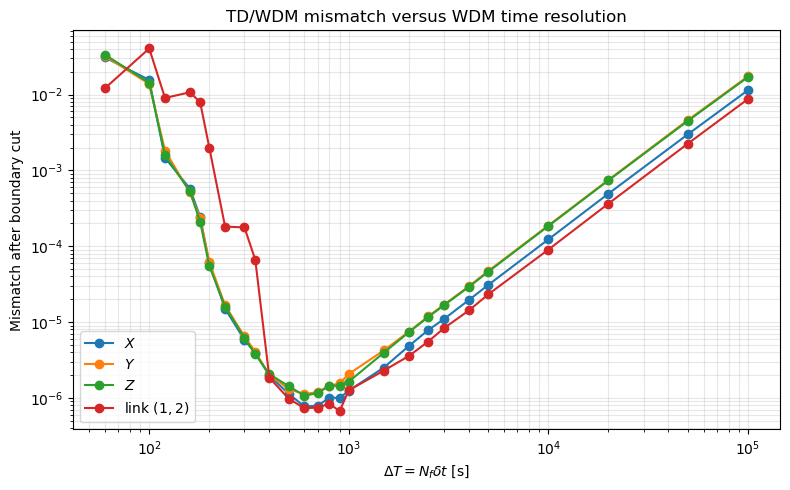

In [12]:
# -------------------------------------------------------------------
# Main plot: mismatch versus DeltaT
# -------------------------------------------------------------------

df_plot = df_deltaT.dropna(
    subset=[
        "X_mismatch_cut",
        "Y_mismatch_cut",
        "Z_mismatch_cut",
        "link_12_mismatch_cut",
    ]
).copy()

fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(
    df_plot["DeltaT"],
    df_plot["X_mismatch_cut"],
    marker="o",
    label=r"$X$",
)

ax.loglog(
    df_plot["DeltaT"],
    df_plot["Y_mismatch_cut"],
    marker="o",
    label=r"$Y$",
)

ax.loglog(
    df_plot["DeltaT"],
    df_plot["Z_mismatch_cut"],
    marker="o",
    label=r"$Z$",
)

ax.loglog(
    df_plot["DeltaT"],
    df_plot["link_12_mismatch_cut"],
    marker="o",
    label=r"link $(1,2)$",
)

ax.set_xlabel(r"$\Delta T = N_f \delta t$ [s]")
ax.set_ylabel("Mismatch after boundary cut")
ax.set_title(r"TD/WDM mismatch versus WDM time resolution")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

fig.tight_layout()

plot_path = DELTA_T_SWEEP_DIR / "deltaT_mismatch_cut_XYZ_link12_basepad_stable_up_to_Nf10000.pdf"
fig.savefig(plot_path, bbox_inches="tight")

print("Saved plot to:", plot_path)

plt.show()

Large-DeltaT power-law fit:


,channel,column,N_points,Nf_min,Nf_max,DeltaT_min,DeltaT_max,slope,slope_minus_2,slope_se,z_like_vs_2,intercept_log10,R2_loglog,RSS_loglog
0,X,X_mismatch_cut,11,100,10000,1000.0,100000.0,1.993224,-0.006776,0.007783,-0.870699,-11.891858,0.999863,0.002252
1,Y,Y_mismatch_cut,11,100,10000,1000.0,100000.0,1.979454,-0.020546,0.006083,-3.377659,-11.648155,0.999915,0.001376
2,Z,Z_mismatch_cut,11,100,10000,1000.0,100000.0,1.999610,-0.000390,0.009282,-0.041967,-11.743468,0.999806,0.003203
3,link_12,link_12_mismatch_cut,11,100,10000,1000.0,100000.0,1.960830,-0.039170,0.020068,-1.951889,-11.878935,0.999058,0.014971


Saved plot to: runs/deltaT_sweep_1yr_basepad_stable/deltaT_large_slope_fit_Nf_ge_100.pdf


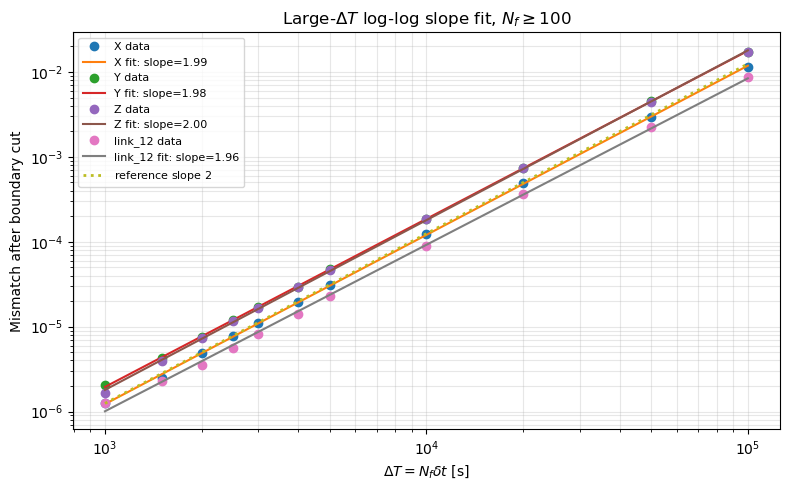

In [13]:
# -------------------------------------------------------------------
# Fit large-DeltaT power-law slope: mismatch ~ DeltaT^p
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the completed sweep table
if "df_deltaT" not in globals():
    raise NameError("df_deltaT is not defined. Load or run the DeltaT sweep first.")

# Fit only the large-DeltaT side
Nf_min_fit = 100

channels_to_fit = {
    "X": "X_mismatch_cut",
    "Y": "Y_mismatch_cut",
    "Z": "Z_mismatch_cut",
    "link_12": "link_12_mismatch_cut",
}

df_fit_source = df_deltaT.copy()
df_fit_source = df_fit_source[df_fit_source["Nf"].astype(int) >= Nf_min_fit].copy()

fit_rows = []

fig, ax = plt.subplots(figsize=(8, 5))

for label, col in channels_to_fit.items():
    if col not in df_fit_source.columns:
        print(f"Skipping {label}: column {col} not found.")
        continue

    # Keep only finite positive points
    mask = (
        np.isfinite(df_fit_source["DeltaT"].to_numpy(dtype=float))
        & np.isfinite(df_fit_source[col].to_numpy(dtype=float))
        & (df_fit_source["DeltaT"].to_numpy(dtype=float) > 0)
        & (df_fit_source[col].to_numpy(dtype=float) > 0)
    )

    df_ch = df_fit_source.loc[mask, ["Nf", "DeltaT", col]].copy()

    if len(df_ch) < 3:
        print(f"Skipping {label}: not enough valid points.")
        continue

    x = np.log10(df_ch["DeltaT"].to_numpy(dtype=float))
    y = np.log10(df_ch[col].to_numpy(dtype=float))

    # Linear fit in log-log space:
    # log10(mismatch) = intercept + slope * log10(DeltaT)
    slope, intercept = np.polyfit(x, y, deg=1)

    y_fit = intercept + slope * x
    residuals = y - y_fit

    dof = len(x) - 2
    rss = float(np.sum(residuals**2))
    tss = float(np.sum((y - np.mean(y))**2))
    r2 = 1.0 - rss / tss if tss > 0 else np.nan

    # Standard error of slope
    x_centered = x - np.mean(x)
    s2 = rss / dof if dof > 0 else np.nan
    slope_se = np.sqrt(s2 / np.sum(x_centered**2)) if dof > 0 else np.nan

    # Difference from slope = 2
    slope_minus_2 = slope - 2.0
    z_like = slope_minus_2 / slope_se if slope_se > 0 else np.nan

    fit_rows.append({
        "channel": label,
        "column": col,
        "N_points": len(df_ch),
        "Nf_min": int(df_ch["Nf"].min()),
        "Nf_max": int(df_ch["Nf"].max()),
        "DeltaT_min": float(df_ch["DeltaT"].min()),
        "DeltaT_max": float(df_ch["DeltaT"].max()),
        "slope": float(slope),
        "slope_minus_2": float(slope_minus_2),
        "slope_se": float(slope_se),
        "z_like_vs_2": float(z_like),
        "intercept_log10": float(intercept),
        "R2_loglog": float(r2),
        "RSS_loglog": float(rss),
    })

    # Plot data
    ax.loglog(
        df_ch["DeltaT"],
        df_ch[col],
        marker="o",
        linestyle="",
        label=fr"{label} data",
    )

    # Plot fitted line over the fitted DeltaT interval
    DeltaT_line = np.logspace(
        np.log10(df_ch["DeltaT"].min()),
        np.log10(df_ch["DeltaT"].max()),
        200,
    )

    mismatch_fit_line = 10.0 ** (intercept + slope * np.log10(DeltaT_line))

    ax.loglog(
        DeltaT_line,
        mismatch_fit_line,
        linestyle="-",
        label=fr"{label} fit: slope={slope:.2f}",
    )

# Add one reference slope-2 line, normalized to the X channel if available
ref_col = "X_mismatch_cut"

df_ref = df_fit_source[
    np.isfinite(df_fit_source["DeltaT"].to_numpy(dtype=float))
    & np.isfinite(df_fit_source[ref_col].to_numpy(dtype=float))
    & (df_fit_source["DeltaT"].to_numpy(dtype=float) > 0)
    & (df_fit_source[ref_col].to_numpy(dtype=float) > 0)
].copy()

if len(df_ref) > 0:
    DeltaT0 = float(df_ref["DeltaT"].iloc[0])
    mismatch0 = float(df_ref[ref_col].iloc[0])

    DeltaT_ref = np.logspace(
        np.log10(df_fit_source["DeltaT"].min()),
        np.log10(df_fit_source["DeltaT"].max()),
        200,
    )

    mismatch_ref = mismatch0 * (DeltaT_ref / DeltaT0) ** 2

    ax.loglog(
        DeltaT_ref,
        mismatch_ref,
        linestyle=":",
        linewidth=2,
        label=r"reference slope $2$",
    )

ax.set_xlabel(r"$\Delta T = N_f \delta t$ [s]")
ax.set_ylabel("Mismatch after boundary cut")
ax.set_title(fr"Large-$\Delta T$ log-log slope fit, $N_f \geq {Nf_min_fit}$")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()

fit_table = pd.DataFrame(fit_rows)

print("Large-DeltaT power-law fit:")
display(fit_table)

plot_path = DELTA_T_SWEEP_DIR / f"deltaT_large_slope_fit_Nf_ge_{Nf_min_fit}.pdf"
fig.savefig(plot_path, bbox_inches="tight")

print("Saved plot to:", plot_path)

plt.show()

Small-DeltaT power-law fit:


,channel,column,N_points,Nf_min,Nf_max,DeltaT_min,DeltaT_max,slope,reference_slope,slope_minus_reference,slope_se,z_like_vs_reference,intercept_log10,R2_loglog,RSS_loglog
0,X,X_mismatch_cut,16,6,100,60.0,1000.0,-4.099493,-2.0,-2.099493,0.368973,-5.690107,5.540741,0.898141,3.837715
1,Y,Y_mismatch_cut,16,6,100,60.0,1000.0,-3.911738,-2.0,-1.911738,0.386998,-4.939916,5.142960,0.879487,4.221846
2,Z,Z_mismatch_cut,16,6,100,60.0,1000.0,-3.934340,-2.0,-1.934340,0.381775,-5.066696,5.180188,0.883528,4.108663
3,link_12,link_12_mismatch_cut,16,6,100,60.0,1000.0,-4.818788,-2.0,-2.818788,0.474073,-5.945889,7.861507,0.880668,6.335427


Saved plot to: runs/deltaT_sweep_1yr_basepad_stable/deltaT_small_slope_fit_Nf_le_100.pdf


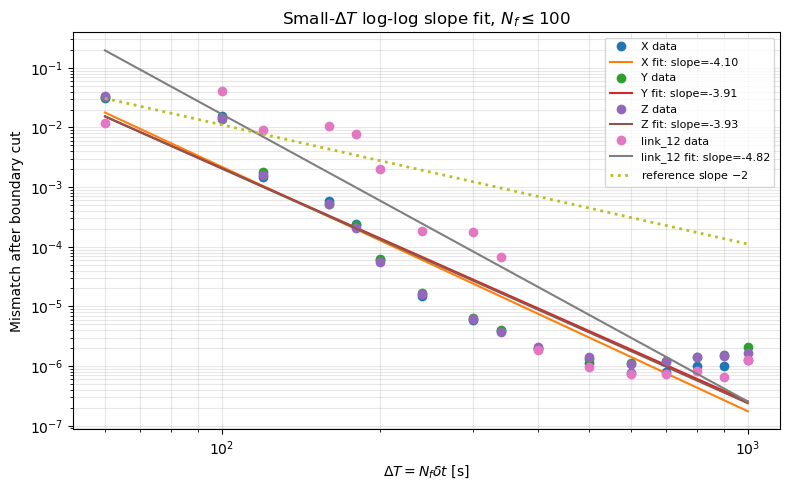

In [14]:
# -------------------------------------------------------------------
# Fit small-DeltaT power-law slope: mismatch ~ DeltaT^p
# using points with Nf <= 40
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "df_deltaT" not in globals():
    raise NameError("df_deltaT is not defined. Load or run the DeltaT sweep first.")

Nf_max_fit = 100
reference_slope = -2.0

channels_to_fit = {
    "X": "X_mismatch_cut",
    "Y": "Y_mismatch_cut",
    "Z": "Z_mismatch_cut",
    "link_12": "link_12_mismatch_cut",
}

df_fit_source = df_deltaT.copy()
df_fit_source = df_fit_source[df_fit_source["Nf"].astype(int) <= Nf_max_fit].copy()

fit_rows = []

fig, ax = plt.subplots(figsize=(8, 5))

for label, col in channels_to_fit.items():
    if col not in df_fit_source.columns:
        print(f"Skipping {label}: column {col} not found.")
        continue

    mask = (
        np.isfinite(df_fit_source["DeltaT"].to_numpy(dtype=float))
        & np.isfinite(df_fit_source[col].to_numpy(dtype=float))
        & (df_fit_source["DeltaT"].to_numpy(dtype=float) > 0)
        & (df_fit_source[col].to_numpy(dtype=float) > 0)
    )

    df_ch = df_fit_source.loc[mask, ["Nf", "DeltaT", col]].copy()

    if len(df_ch) < 3:
        print(f"Skipping {label}: not enough valid points.")
        continue

    x = np.log10(df_ch["DeltaT"].to_numpy(dtype=float))
    y = np.log10(df_ch[col].to_numpy(dtype=float))

    slope, intercept = np.polyfit(x, y, deg=1)

    y_fit = intercept + slope * x
    residuals = y - y_fit

    dof = len(x) - 2
    rss = float(np.sum(residuals**2))
    tss = float(np.sum((y - np.mean(y))**2))
    r2 = 1.0 - rss / tss if tss > 0 else np.nan

    x_centered = x - np.mean(x)
    s2 = rss / dof if dof > 0 else np.nan
    slope_se = np.sqrt(s2 / np.sum(x_centered**2)) if dof > 0 else np.nan

    slope_minus_ref = slope - reference_slope
    z_like = slope_minus_ref / slope_se if slope_se > 0 else np.nan

    fit_rows.append({
        "channel": label,
        "column": col,
        "N_points": len(df_ch),
        "Nf_min": int(df_ch["Nf"].min()),
        "Nf_max": int(df_ch["Nf"].max()),
        "DeltaT_min": float(df_ch["DeltaT"].min()),
        "DeltaT_max": float(df_ch["DeltaT"].max()),
        "slope": float(slope),
        "reference_slope": float(reference_slope),
        "slope_minus_reference": float(slope_minus_ref),
        "slope_se": float(slope_se),
        "z_like_vs_reference": float(z_like),
        "intercept_log10": float(intercept),
        "R2_loglog": float(r2),
        "RSS_loglog": float(rss),
    })

    ax.loglog(
        df_ch["DeltaT"],
        df_ch[col],
        marker="o",
        linestyle="",
        label=fr"{label} data",
    )

    DeltaT_line = np.logspace(
        np.log10(df_ch["DeltaT"].min()),
        np.log10(df_ch["DeltaT"].max()),
        200,
    )

    mismatch_fit_line = 10.0 ** (intercept + slope * np.log10(DeltaT_line))

    ax.loglog(
        DeltaT_line,
        mismatch_fit_line,
        linestyle="-",
        label=fr"{label} fit: slope={slope:.2f}",
    )

# Reference slope line, normalized to X at the first fitted point
ref_col = "X_mismatch_cut"

df_ref = df_fit_source[
    np.isfinite(df_fit_source["DeltaT"].to_numpy(dtype=float))
    & np.isfinite(df_fit_source[ref_col].to_numpy(dtype=float))
    & (df_fit_source["DeltaT"].to_numpy(dtype=float) > 0)
    & (df_fit_source[ref_col].to_numpy(dtype=float) > 0)
].copy()

if len(df_ref) > 0:
    DeltaT0 = float(df_ref["DeltaT"].iloc[0])
    mismatch0 = float(df_ref[ref_col].iloc[0])

    DeltaT_ref = np.logspace(
        np.log10(df_fit_source["DeltaT"].min()),
        np.log10(df_fit_source["DeltaT"].max()),
        200,
    )

    mismatch_ref = mismatch0 * (DeltaT_ref / DeltaT0) ** reference_slope

    ax.loglog(
        DeltaT_ref,
        mismatch_ref,
        linestyle=":",
        linewidth=2,
        label=fr"reference slope ${reference_slope:g}$",
    )

ax.set_xlabel(r"$\Delta T = N_f \delta t$ [s]")
ax.set_ylabel("Mismatch after boundary cut")
ax.set_title(fr"Small-$\Delta T$ log-log slope fit, $N_f \leq {Nf_max_fit}$")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()

fit_table_small = pd.DataFrame(fit_rows)

print("Small-DeltaT power-law fit:")
display(fit_table_small)

plot_path = DELTA_T_SWEEP_DIR / f"deltaT_small_slope_fit_Nf_le_{Nf_max_fit}.pdf"
fig.savefig(plot_path, bbox_inches="tight")

print("Saved plot to:", plot_path)

plt.show()

Large-DeltaT fits:


,channel,fit_range,N_points,Nf_min,Nf_max,DeltaT_min,DeltaT_max,slope,intercept_log10,R2_loglog
0,X,Nf >= 100,11,100,10000,1000.0,100000.0,1.993224,-11.891858,0.999863
1,Y,Nf >= 100,11,100,10000,1000.0,100000.0,1.979454,-11.648155,0.999915
2,Z,Nf >= 100,11,100,10000,1000.0,100000.0,1.999610,-11.743468,0.999806
3,"link $(1,2)$",Nf >= 100,11,100,10000,1000.0,100000.0,1.960830,-11.878935,0.999058


Small-DeltaT fits:


,channel,fit_range,N_points,Nf_min,Nf_max,DeltaT_min,DeltaT_max,slope,intercept_log10,R2_loglog
0,X,Nf <= 60,12,6,60,60.0,600.0,-5.259612,8.105166,0.961853
1,Y,Nf <= 60,12,6,60,60.0,600.0,-5.158664,7.898704,0.960782
2,Z,Nf <= 60,12,6,60,60.0,600.0,-5.156172,7.879680,0.958704
3,"link $(1,2)$",Nf <= 60,12,6,60,60.0,600.0,-5.302007,8.936710,0.833422


Saved plot to: runs/deltaT_sweep_1yr_basepad_stable/deltaT_mismatch_clean_with_slope2_and_slope_minus5_guides.pdf


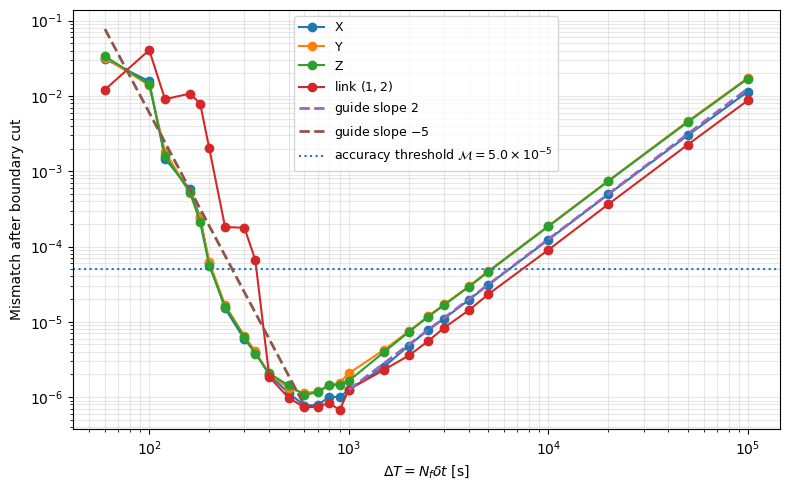

In [17]:
# -------------------------------------------------------------------
# Clean main plot with large-DeltaT slope-2 guide line,
# small-DeltaT slope--4 guide line,
# and printed slope-fit diagnostics
# -------------------------------------------------------------------

# Same mismatch cutoff used elsewhere for accepting timing/accuracy cases.
MISMATCH_CUTOFF = float(globals().get("MISMATCH_TIMING_THRESHOLD", 5e-5))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "df_deltaT" not in globals():
    raise NameError("df_deltaT is not defined. Load or run the DeltaT sweep first.")

df_plot = df_deltaT.copy()
df_plot = df_plot.sort_values("DeltaT").reset_index(drop=True)

channels = {
    "X": "X_mismatch_cut",
    "Y": "Y_mismatch_cut",
    "Z": "Z_mismatch_cut",
    r"link $(1,2)$": "link_12_mismatch_cut",
}


def fit_loglog_slope(df, col, Nf_min=None, Nf_max=None):
    """
    Fit log10(mismatch) = a + p log10(DeltaT).
    """
    d = df.copy()

    if Nf_min is not None:
        d = d[d["Nf"].astype(int) >= int(Nf_min)]

    if Nf_max is not None:
        d = d[d["Nf"].astype(int) <= int(Nf_max)]

    mask = (
        np.isfinite(d["DeltaT"].to_numpy(dtype=float))
        & np.isfinite(d[col].to_numpy(dtype=float))
        & (d["DeltaT"].to_numpy(dtype=float) > 0)
        & (d[col].to_numpy(dtype=float) > 0)
    )

    d = d.loc[mask, ["Nf", "DeltaT", col]].copy()

    if len(d) < 3:
        return None

    x = np.log10(d["DeltaT"].to_numpy(dtype=float))
    y = np.log10(d[col].to_numpy(dtype=float))

    slope, intercept = np.polyfit(x, y, deg=1)

    y_fit = intercept + slope * x
    residuals = y - y_fit
    rss = float(np.sum(residuals**2))
    tss = float(np.sum((y - np.mean(y))**2))
    r2 = 1.0 - rss / tss if tss > 0 else np.nan

    return {
        "N_points": len(d),
        "Nf_min": int(d["Nf"].min()),
        "Nf_max": int(d["Nf"].max()),
        "DeltaT_min": float(d["DeltaT"].min()),
        "DeltaT_max": float(d["DeltaT"].max()),
        "slope": float(slope),
        "intercept_log10": float(intercept),
        "R2_loglog": float(r2),
    }


# -------------------------------------------------------------------
# Fit diagnostics, not all plotted
# -------------------------------------------------------------------

large_fit_rows = []
small_fit_rows = []

for label, col in channels.items():
    if col not in df_plot.columns:
        continue

    large = fit_loglog_slope(df_plot, col, Nf_min=100)
    small = fit_loglog_slope(df_plot, col, Nf_max=60)

    if large is not None:
        large_fit_rows.append({"channel": label, "fit_range": "Nf >= 100", **large})

    if small is not None:
        small_fit_rows.append({"channel": label, "fit_range": "Nf <= 60", **small})

df_large_fit = pd.DataFrame(large_fit_rows)
df_small_fit = pd.DataFrame(small_fit_rows)

print("Large-DeltaT fits:")
display(df_large_fit)

print("Small-DeltaT fits:")
display(df_small_fit)


# -------------------------------------------------------------------
# Main plot
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

for label, col in channels.items():
    if col not in df_plot.columns:
        print(f"Skipping {label}: column {col} not found.")
        continue

    mask = (
        np.isfinite(df_plot["DeltaT"].to_numpy(dtype=float))
        & np.isfinite(df_plot[col].to_numpy(dtype=float))
        & (df_plot["DeltaT"].to_numpy(dtype=float) > 0)
        & (df_plot[col].to_numpy(dtype=float) > 0)
    )

    d = df_plot.loc[mask, ["Nf", "DeltaT", col]].copy()

    if len(d) == 0:
        continue

    ax.loglog(
        d["DeltaT"],
        d[col],
        marker="o",
        label=label,
    )


# -------------------------------------------------------------------
# Slope +2 guide line on the large-DeltaT side: Nf >= 100
# -------------------------------------------------------------------

guide_col = "X_mismatch_cut"
Nf_guide_min = 100

d_guide_anchor = df_plot[
    (df_plot["Nf"].astype(int) >= Nf_guide_min)
    & np.isfinite(df_plot["DeltaT"].to_numpy(dtype=float))
    & np.isfinite(df_plot[guide_col].to_numpy(dtype=float))
    & (df_plot["DeltaT"].to_numpy(dtype=float) > 0)
    & (df_plot[guide_col].to_numpy(dtype=float) > 0)
].copy()

if len(d_guide_anchor) > 0:
    d_guide_anchor = d_guide_anchor.sort_values("DeltaT")

    # Anchor at the first large-DeltaT point, i.e. Nf >= 100 boundary.
    DeltaT0 = float(d_guide_anchor["DeltaT"].iloc[0])
    mismatch0 = float(d_guide_anchor[guide_col].iloc[0])

    DeltaT_min = float(d_guide_anchor["DeltaT"].min())
    DeltaT_max = float(d_guide_anchor["DeltaT"].max())

    DeltaT_line = np.logspace(
        np.log10(DeltaT_min),
        np.log10(DeltaT_max),
        200,
    )

    mismatch_line = mismatch0 * (DeltaT_line / DeltaT0) ** 2

    ax.loglog(
        DeltaT_line,
        mismatch_line,
        linestyle="--",
        linewidth=2,
        label=r"guide slope $2$",
    )


# -------------------------------------------------------------------
# Slope -4 guide line on the small-DeltaT side: Nf <= 100
# -------------------------------------------------------------------

guide_col_small = "X_mismatch_cut"
Nf_guide_max_small = 60

d_guide_anchor_small = df_plot[
    (df_plot["Nf"].astype(int) <= Nf_guide_max_small)
    & np.isfinite(df_plot["DeltaT"].to_numpy(dtype=float))
    & np.isfinite(df_plot[guide_col_small].to_numpy(dtype=float))
    & (df_plot["DeltaT"].to_numpy(dtype=float) > 0)
    & (df_plot[guide_col_small].to_numpy(dtype=float) > 0)
].copy()

if len(d_guide_anchor_small) > 0:
    d_guide_anchor_small = d_guide_anchor_small.sort_values("DeltaT")

    # Anchor at the largest small-DeltaT point, i.e. Nf <= 100 boundary.
    DeltaT0_small = float(d_guide_anchor_small["DeltaT"].iloc[-1])
    mismatch0_small = float(d_guide_anchor_small[guide_col_small].iloc[-1])

    DeltaT_min_small = float(d_guide_anchor_small["DeltaT"].min())
    DeltaT_max_small = float(d_guide_anchor_small["DeltaT"].max())

    DeltaT_line_small = np.logspace(
        np.log10(DeltaT_min_small),
        np.log10(DeltaT_max_small),
        200,
    )

    mismatch_line_small = mismatch0_small * (DeltaT_line_small / DeltaT0_small) ** (-5)

    ax.loglog(
        DeltaT_line_small,
        mismatch_line_small,
        linestyle="--",
        linewidth=2,
        label=r"guide slope $-5$",
    )

ax.axhline(
    MISMATCH_CUTOFF,
    linestyle=":",
    linewidth=1.5,
    label=r"accuracy threshold $\mathcal{{M}}={5.0 \times 10^{-5} }$",
)

# -------------------------------------------------------------------
# Formatting
# -------------------------------------------------------------------

ax.set_xlabel(r"$\Delta T = N_f \delta t$ [s]")
ax.set_ylabel("Mismatch after boundary cut")
# ax.set_title(r"TD/WDM mismatch versus WDM time resolution")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)

fig.tight_layout()

plot_path = DELTA_T_SWEEP_DIR / "deltaT_mismatch_clean_with_slope2_and_slope_minus5_guides.pdf"
fig.savefig(plot_path, bbox_inches="tight")

print("Saved plot to:", plot_path)

plt.show()

In [18]:
# -------------------------------------------------------------------
# Select DeltaT values for timing based on mismatch threshold
# -------------------------------------------------------------------

import numpy as np
import pandas as pd

if "df_deltaT" not in globals():
    raise NameError("df_deltaT is not defined. Run or load the DeltaT mismatch sweep first.")

MISMATCH_TIMING_THRESHOLD = 5e-5

mismatch_cols_for_selection = [
    "X_mismatch_cut",
    "Y_mismatch_cut",
    "Z_mismatch_cut",
    "link_12_mismatch_cut",
]

missing_cols = [c for c in mismatch_cols_for_selection if c not in df_deltaT.columns]
if missing_cols:
    raise KeyError(f"Missing mismatch columns in df_deltaT: {missing_cols}")

df_timing_candidates = df_deltaT.copy()
df_timing_candidates = df_timing_candidates.sort_values("Nf").reset_index(drop=True)

df_timing_candidates["max_mismatch_cut"] = df_timing_candidates[
    mismatch_cols_for_selection
].max(axis=1)

df_timing_candidates["accuracy_acceptable"] = (
    np.isfinite(df_timing_candidates["max_mismatch_cut"])
    & (df_timing_candidates["max_mismatch_cut"] < MISMATCH_TIMING_THRESHOLD)
)

df_timing_selected = df_timing_candidates[
    df_timing_candidates["accuracy_acceptable"]
].copy()

Nf_timing_grid = [int(x) for x in df_timing_selected["Nf"].to_numpy()]

print("Mismatch threshold:", MISMATCH_TIMING_THRESHOLD)
print()
print("Selected Nf values for timing:")
print(Nf_timing_grid)
print()
print("Selected timing candidates:")
display(
    df_timing_selected[
        [
            "Nf",
            "DeltaT",
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
            "max_mismatch_cut",
        ]
    ]
)

print()
print("Rejected candidates:")
display(
    df_timing_candidates[
        ~df_timing_candidates["accuracy_acceptable"]
    ][
        [
            "Nf",
            "DeltaT",
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
            "max_mismatch_cut",
        ]
    ]
)

Mismatch threshold: 5e-05

Selected Nf values for timing:
[40, 50, 60, 70, 80, 90, 100, 150, 200, 250, 300, 400, 500]

Selected timing candidates:


,Nf,DeltaT,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut,max_mismatch_cut
9,40,400.0,1.965603e-06,0.000002,0.000002,1.847513e-06,0.000002
10,50,500.0,1.132928e-06,0.000001,0.000001,9.781449e-07,0.000001
11,60,600.0,7.718529e-07,0.000001,0.000001,7.307527e-07,0.000001
12,70,700.0,7.906681e-07,0.000001,0.000001,7.472408e-07,0.000001
13,80,800.0,1.010315e-06,0.000001,0.000001,8.398081e-07,0.000001
14,90,900.0,1.000854e-06,0.000002,0.000001,6.688389e-07,0.000002
15,100,1000.0,1.246830e-06,0.000002,0.000002,1.260805e-06,0.000002
16,150,1500.0,2.519964e-06,0.000004,0.000004,2.298884e-06,0.000004
17,200,2000.0,4.836279e-06,0.000007,0.000007,3.569658e-06,0.000007
18,250,2500.0,7.841911e-06,0.000012,0.000012,5.537818e-06,0.000012



Rejected candidates:


,Nf,DeltaT,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut,max_mismatch_cut
0,6,60.0,0.030882,0.032190,0.033513,0.012114,0.033513
1,10,100.0,0.015607,0.013818,0.014338,0.040581,0.040581
2,12,120.0,0.001465,0.001825,0.001591,0.009031,0.009031
3,16,160.0,0.000576,0.000512,0.000528,0.010735,0.010735
4,18,180.0,0.000244,0.000236,0.000210,0.007923,0.007923
5,20,200.0,0.000059,0.000062,0.000055,0.002003,0.002003
6,24,240.0,0.000015,0.000017,0.000016,0.000182,0.000182
7,30,300.0,0.000006,0.000006,0.000006,0.000177,0.000177
8,34,340.0,0.000004,0.000004,0.000004,0.000066,0.000066
22,1000,10000.0,0.000123,0.000188,0.000185,0.000090,0.000188


In [19]:
# -------------------------------------------------------------------
# Fixed diagnostic timing configuration for Nf / DeltaT sensitivity
# Uses row-chunked backend without lag blocking
# -------------------------------------------------------------------

from WDM_LISAresponse.code.lisa_response.TDI import (
    precompute_gen2_michelson_wdm_geometry,
    precompute_gen2_michelson_wdm_waveform,
    gen2_michelson_wdm_from_waveform_precomputed,
)

# Restore WDM filter parameter safely in case plotting code overwrote `d`
wdm_settings = td_metadata.get("wdm_settings", {})
WDM_D = int(wdm_settings.get("d", 4))
d = WDM_D

TIMING_L_TRUNC = 25

# Diagnostic/sensitivity backend:
# - keeps row chunking
# - removes lag-blocking so timing trends are not affected by lag-block boundaries
# - keeps L, row chunk size, interpolation mode, precision fixed
TIMING_SHIFT_KWARGS = {
    "assembly_backend": "lagfirst_chunked",
    "assembly_precision": "complex64",
    "row_chunk_size": 2048,
    "tl_tp_mode": "interp",
    "tl_tp_interp_points": 16,
    "tl_tp_interp_pad": 0.0,
    "tl_tp_interp_kind": "linear",
    "tl_tp_interp_backend": "numpy",
    "batch_chunk": 1,
}

TIMING_TDI_ASSEMBLY_MODE = "batch_map"
TIMING_ACCUMULATOR_CHUNK = 1

# A0 is static setup for this Nf. We do not use it in the main timing plot.
A0_GEOM_WARM_RUNS = 0
A0_GEOM_REPEAT = 1

# Main benchmark timings.
# Warm once, then take median of 5 runs.
A1_WAVE_WARM_RUNS = 1
B_TDI_WARM_RUNS = 1

A1_WAVE_REPEAT = 5
B_TDI_REPEAT = 5

# For the main timing curves, keep profiling off.
# Profiling changes the timing path and is better used only in separate diagnostics.
PROFILE_SHIFT_STAGES = False
RETURN_SHIFT_PROFILE = False

TIMING_CONFIG_LABEL = (
    f"chunked_L{TIMING_L_TRUNC}_R{TIMING_SHIFT_KWARGS['row_chunk_size']}"
    f"_BC{TIMING_SHIFT_KWARGS['batch_chunk']}"
    f"_ip{TIMING_SHIFT_KWARGS['tl_tp_interp_points']}_no_m0"
)

print("Timing configuration:")
print("  label:", TIMING_CONFIG_LABEL)
print("  WDM_D:", WDM_D)
print("  L_trunc:", TIMING_L_TRUNC)
print("  n_lags:", 2 * TIMING_L_TRUNC + 1)
print("  TDI assembly mode:", TIMING_TDI_ASSEMBLY_MODE)
print("  profiling:", PROFILE_SHIFT_STAGES, RETURN_SHIFT_PROFILE)
print("  shift kwargs:")
for k, v in TIMING_SHIFT_KWARGS.items():
    print(f"    {k}: {v}")

Timing configuration:
  label: chunked_L25_R2048_BC1_ip16_no_m0
  WDM_D: 4
  L_trunc: 25
  n_lags: 51
  TDI assembly mode: batch_map
  profiling: False False
  shift kwargs:
    assembly_backend: lagfirst_chunked
    assembly_precision: complex64
    row_chunk_size: 2048
    tl_tp_mode: interp
    tl_tp_interp_points: 16
    tl_tp_interp_pad: 0.0
    tl_tp_interp_kind: linear
    tl_tp_interp_backend: numpy
    batch_chunk: 1


In [20]:
# -------------------------------------------------------------------
# Timing helpers: median over repeated runs
# -------------------------------------------------------------------

import time
import gc
import numpy as np


def sync_result(x):
    """
    Force completion of JAX work before stopping timers.
    """
    try:
        leaves = jax.tree_util.tree_leaves(x)
        for y in leaves:
            if hasattr(y, "block_until_ready"):
                y.block_until_ready()
    except Exception:
        pass

    return x


def time_call_stats(fn, warm=0, repeat=5, sync=True):
    """
    Run fn with warm-up, then return output and timing statistics.
    """
    warm = max(0, int(warm))
    repeat = max(1, int(repeat))

    for _ in range(warm):
        out = fn()
        if sync:
            sync_result(out)

    timings = []
    out = None

    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn()
        if sync:
            sync_result(out)
        t1 = time.perf_counter()
        timings.append(t1 - t0)

    timings = np.asarray(timings, dtype=float)

    return out, {
        "median_s": float(np.median(timings)),
        "mean_s": float(np.mean(timings)),
        "std_s": float(np.std(timings)),
        "min_s": float(np.min(timings)),
        "max_s": float(np.max(timings)),
        "repeat": int(repeat),
        "all_s": timings,
    }


def clear_jax_memory():
    try:
        import jax
        jax.clear_caches()
    except Exception:
        pass

    gc.collect()


def require_timing_inputs():
    required = [
        "times_base",
        "hplus_base",
        "hcross_base",
        "theta",
        "phi",
        "orbits_trailing",
        "q_wdm",
        "WDM_D",
    ]

    missing = [name for name in required if name not in globals()]
    if missing:
        raise NameError(f"Missing required variables for timing: {missing}")


print("Timing helpers loaded.")

Timing helpers loaded.


In [21]:
# -------------------------------------------------------------------
# One DeltaT timing case with A0 excluded from main timing
# -------------------------------------------------------------------

def run_tdi_deltaT_timing_case(Nf):
    require_timing_inputs()

    Nf = int(Nf)
    DeltaT = float(Nf * dt)

    print()
    print("=" * 100)
    print(f"Timing Nf={Nf}, DeltaT={DeltaT:.6e} s")
    print("=" * 100)

    shift_kwargs = dict(TIMING_SHIFT_KWARGS)

    lag_block_size_value = shift_kwargs.get("lag_block_size", None)
    timing_config_label = globals().get("TIMING_CONFIG_LABEL", "deltaT_timing_config")

    # ------------------------------------------------------------------
    # A0: static geometry/WDM-grid precompute
    # ------------------------------------------------------------------
    # This depends on the time grid, sky position, orbit, Nf, L, etc.
    # It is done once per Nf and is not part of the repeated waveform timing.
    # ------------------------------------------------------------------

    def run_geometry_precompute():
        return precompute_gen2_michelson_wdm_geometry(
            times_base,
            theta,
            phi,
            orbits_trailing,
            Nf=Nf,
            L_trunc=TIMING_L_TRUNC,
            q=q_wdm,
            d=WDM_D,
            calc_m0=CALC_M0,
            variable_shift_kwargs=shift_kwargs,
        )

    tdi_geom_precomp, geom_timing = time_call_stats(
        run_geometry_precompute,
        warm=A0_GEOM_WARM_RUNS,
        repeat=A0_GEOM_REPEAT,
    )

    if not isinstance(tdi_geom_precomp, dict):
        raise TypeError(f"Expected geometry precompute dict, got {type(tdi_geom_precomp)}")

    if "wdm" not in tdi_geom_precomp:
        raise RuntimeError("Geometry precompute does not contain 'wdm'.")

    wdm_obj = tdi_geom_precomp["wdm"]

    print("A0 static setup:")
    print(f"  geometry_precompute_s: {geom_timing['median_s']:.6f}")
    print(f"  WDM shape: Nt={wdm_obj.Nt}, Nf={wdm_obj.Nf}, N={wdm_obj.N}")
    print(f"  DeltaT from WDM: {wdm_obj.dT:.6e}")

    # ------------------------------------------------------------------
    # A1: waveform-specific one-arm stage
    # ------------------------------------------------------------------
    # This starts from hplus_base/hcross_base.
    # It does NOT include FEW/waveform generation.
    # It does include WDM waveform-context construction and one-arm responses.
    # ------------------------------------------------------------------

    a1_internal_rows = []

    def run_waveform_precompute():
        out = precompute_gen2_michelson_wdm_waveform(
            tdi_geom_precomp,
            hplus_base,
            hcross_base,
            variable_shift_kwargs=shift_kwargs,
        )

        # Store internal timings for the final, synchronized call.
        a1_internal_rows.append({
            "waveform_context_build_s": float(out.get("waveform_context_build_s", np.nan)),
            "six_link_compute_s": float(out.get("six_link_compute_s", np.nan)),
            "job_build_s": float(out.get("job_build_s", np.nan)),
        })

        return out

    tdi_wave_precomp, wave_timing = time_call_stats(
        run_waveform_precompute,
        warm=A1_WAVE_WARM_RUNS,
        repeat=A1_WAVE_REPEAT,
    )

    if not isinstance(tdi_wave_precomp, dict):
        raise TypeError(f"Expected waveform precompute dict, got {type(tdi_wave_precomp)}")

    n_tdi_jobs = len(tdi_wave_precomp.get("all_jobs", []))

    # Internal timings from each measured/warm call.
    # Ignore first warm rows by taking the last A1_WAVE_REPEAT rows.
    a1_measured_internal = a1_internal_rows[-A1_WAVE_REPEAT:]

    a1_context_values = np.asarray(
        [r["waveform_context_build_s"] for r in a1_measured_internal],
        dtype=float,
    )
    a1_links_values = np.asarray(
        [r["six_link_compute_s"] for r in a1_measured_internal],
        dtype=float,
    )
    a1_jobs_values = np.asarray(
        [r["job_build_s"] for r in a1_measured_internal],
        dtype=float,
    )

    a1_context_median = float(np.nanmedian(a1_context_values))
    a1_links_median = float(np.nanmedian(a1_links_values))
    a1_jobs_median = float(np.nanmedian(a1_jobs_values))

    print("A1 waveform/one-arm stage:")
    print(f"  A1 median_s:                 {wave_timing['median_s']:.6f}")
    print(f"  waveform_context median_s:   {a1_context_median:.6f}")
    print(f"  six_link_compute median_s:   {a1_links_median:.6f}")
    print(f"  job_build median_s:          {a1_jobs_median:.6f}")
    print(f"  n_tdi_jobs:                  {n_tdi_jobs}")

    # ------------------------------------------------------------------
    # B: downstream TDI stage
    # ------------------------------------------------------------------
    # This takes the precomputed one-arm/job representation and applies
    # the downstream TDI time shifts/assembly to produce X,Y,Z.
    # ------------------------------------------------------------------

    shift_profile_rows = []

    def run_downstream_tdi():
        profiled_out = gen2_michelson_wdm_from_waveform_precomputed(
            tdi_wave_precomp,
            variable_shift_kwargs=shift_kwargs,
            L_trunc=TIMING_L_TRUNC,
            Nf=Nf,
            tdi_assembly_mode=TIMING_TDI_ASSEMBLY_MODE,
            accumulator_chunk=TIMING_ACCUMULATOR_CHUNK,
            profile_shift_stages=PROFILE_SHIFT_STAGES,
            profile_label=f"DeltaT_timing_Nf{Nf}",
            return_shift_profile=RETURN_SHIFT_PROFILE,
        )

        if RETURN_SHIFT_PROFILE:
            out, profile = profiled_out
            shift_profile_rows.append(dict(profile))
            return out, profile

        return profiled_out

    profiled_out, downstream_timing = time_call_stats(
        run_downstream_tdi,
        warm=B_TDI_WARM_RUNS,
        repeat=B_TDI_REPEAT,
    )

    if RETURN_SHIFT_PROFILE:
        out, shift_profile = profiled_out
    else:
        out = profiled_out
        shift_profile = {}

    X_wdm, Y_wdm, Z_wdm = out

    finite = (
        np.all(np.isfinite(np.asarray(X_wdm)))
        and np.all(np.isfinite(np.asarray(Y_wdm)))
        and np.all(np.isfinite(np.asarray(Z_wdm)))
    )

    print("B downstream TDI stage:")
    print(f"  B median_s:                  {downstream_timing['median_s']:.6f}")
    print(f"  output shape:                {np.asarray(X_wdm).shape}")
    print(f"  finite:                      {finite}")

    # Median internal B profile over measured calls.
    b_measured_profiles = shift_profile_rows[-B_TDI_REPEAT:]

    def median_profile_value(key):
        values = np.asarray(
            [float(p.get(key, np.nan)) for p in b_measured_profiles],
            dtype=float,
        )
        return float(np.nanmedian(values)) if values.size > 0 else np.nan

    profile_total_s = median_profile_value("total_s")
    tl_tp_prepare_s = median_profile_value("tl_tp_prepare_s")
    jax_assembly_s = median_profile_value("jax_assembly_s")
    postprocess_s = median_profile_value("postprocess_s")
    other_s = median_profile_value("other_s")

    total_next_waveform_s = wave_timing["median_s"] + downstream_timing["median_s"]

    B_per_job_ms = (
        1e3 * downstream_timing["median_s"] / n_tdi_jobs
        if n_tdi_jobs > 0
        else np.nan
    )

    row = {
        "timing_config_label": str(timing_config_label),
        "config_label": str(timing_config_label),

        "Nf": int(Nf),
        "DeltaT": float(DeltaT),
        "Nt": int(wdm_obj.Nt),
        "N": int(wdm_obj.N),
        "coeffs_per_channel": int(wdm_obj.Nt * wdm_obj.Nf),

        "L_trunc": int(TIMING_L_TRUNC),
        "n_lags": int(2 * TIMING_L_TRUNC + 1),

        "assembly_backend": shift_kwargs["assembly_backend"],
        "assembly_precision": shift_kwargs["assembly_precision"],
        "row_chunk_size": int(shift_kwargs["row_chunk_size"]),
        "lag_block_size": (
            np.nan if lag_block_size_value is None else int(lag_block_size_value)
        ),
        "interp_points": int(shift_kwargs["tl_tp_interp_points"]),
        "tl_tp_interp_backend": str(shift_kwargs.get("tl_tp_interp_backend", "")),
        "batch_chunk": int(shift_kwargs.get("batch_chunk", -1)),
        "tdi_assembly_mode": TIMING_TDI_ASSEMBLY_MODE,

        "profile_shift_stages": bool(PROFILE_SHIFT_STAGES),
        "return_shift_profile": bool(RETURN_SHIFT_PROFILE),

        # Static setup, reported but not included in main repeated runtime.
        "A0_geometry_precompute_s": float(geom_timing["median_s"]),

        # A1: waveform input -> one-arm link responses/job representation.
        "A1_waveform_precompute_median_s": float(wave_timing["median_s"]),
        "A1_waveform_precompute_mean_s": float(wave_timing["mean_s"]),
        "A1_waveform_precompute_std_s": float(wave_timing["std_s"]),

        "A1_waveform_context_build_median_s": float(a1_context_median),
        "A1_six_link_compute_median_s": float(a1_links_median),
        "A1_job_build_median_s": float(a1_jobs_median),

        # B: one-arm/job representation -> X,Y,Z.
        "B_downstream_tdi_median_s": float(downstream_timing["median_s"]),
        "B_downstream_tdi_mean_s": float(downstream_timing["mean_s"]),
        "B_downstream_tdi_std_s": float(downstream_timing["std_s"]),

        "B_per_job_ms": float(B_per_job_ms),

        # Repeated per-waveform response cost.
        "total_A1_plus_B_median_s": float(total_next_waveform_s),

        # B internal profile. These are NaN when profiling is disabled.
        "B_profile_total_s": float(profile_total_s),
        "B_tl_tp_prepare_s": float(tl_tp_prepare_s),
        "B_jax_assembly_s": float(jax_assembly_s),
        "B_postprocess_s": float(postprocess_s),
        "B_other_s": float(other_s),

        "B_tl_tp_prepare_frac": (
            tl_tp_prepare_s / profile_total_s if profile_total_s > 0 else np.nan
        ),
        "B_jax_assembly_frac": (
            jax_assembly_s / profile_total_s if profile_total_s > 0 else np.nan
        ),
        "B_postprocess_frac": (
            postprocess_s / profile_total_s if profile_total_s > 0 else np.nan
        ),
        "B_other_frac": (
            other_s / profile_total_s if profile_total_s > 0 else np.nan
        ),

        "n_tdi_jobs": int(n_tdi_jobs),
        "finite": bool(finite),

        "A1_repeat": int(A1_WAVE_REPEAT),
        "B_repeat": int(B_TDI_REPEAT),
    }

    # Add mismatch information from df_deltaT.
    if "df_timing_selected" in globals():
        match = df_timing_selected[df_timing_selected["Nf"].astype(int) == Nf]
    else:
        match = df_deltaT[df_deltaT["Nf"].astype(int) == Nf]

    if len(match) > 0:
        mrow = match.iloc[0]

        for col in [
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
            "max_mismatch_cut",
        ]:
            if col in mrow.index:
                row[col] = float(mrow[col])

    del (
        tdi_geom_precomp,
        tdi_wave_precomp,
        out,
        X_wdm,
        Y_wdm,
        Z_wdm,
    )

    clear_jax_memory()

    return row


print("run_tdi_deltaT_timing_case loaded.")

run_tdi_deltaT_timing_case loaded.


In [22]:
# -------------------------------------------------------------------
# Run DeltaT timing sweep over accuracy-acceptable Nf values
# -------------------------------------------------------------------

if "Nf_timing_grid" not in globals():
    raise NameError("Nf_timing_grid is not defined. Run the candidate-selection cell first.")

if len(Nf_timing_grid) == 0:
    raise RuntimeError("No Nf values passed the mismatch threshold.")

if "TIMING_CONFIG_LABEL" not in globals():
    TIMING_CONFIG_LABEL = (
        f"chunked_L{TIMING_L_TRUNC}_R{TIMING_SHIFT_KWARGS['row_chunk_size']}"
        f"_BC{TIMING_SHIFT_KWARGS.get('batch_chunk', 1)}"
        f"_ip{TIMING_SHIFT_KWARGS['tl_tp_interp_points']}_no_m0"
    )

timing_results = []

timing_partial_path = (
    DELTA_T_SWEEP_DIR
    / f"deltaT_timing_acceptable_mismatch_{TIMING_CONFIG_LABEL}_partial.csv"
)

timing_final_path = (
    DELTA_T_SWEEP_DIR
    / f"deltaT_timing_acceptable_mismatch_{TIMING_CONFIG_LABEL}_full.csv"
)

# Fresh run
for path in [timing_partial_path, timing_final_path]:
    if path.exists():
        path.unlink()
        print("Removed old file:", path)

print("Timing output files:")
print("  partial:", timing_partial_path)
print("  final:  ", timing_final_path)

for Nf in Nf_timing_grid:
    row = run_tdi_deltaT_timing_case(Nf)
    timing_results.append(row)

    df_timing = pd.DataFrame(timing_results)
    df_timing = df_timing.sort_values("DeltaT").reset_index(drop=True)
    df_timing.to_csv(timing_partial_path, index=False)

    print("Saved partial timing results to:", timing_partial_path)

df_timing = pd.DataFrame(timing_results)
df_timing = df_timing.sort_values("DeltaT").reset_index(drop=True)
df_timing.to_csv(timing_final_path, index=False)

print()
print("Saved final timing results to:", timing_final_path)

display(df_timing)

Removed old file: runs/deltaT_sweep_1yr_basepad_stable/deltaT_timing_acceptable_mismatch_chunked_L25_R2048_BC1_ip16_no_m0_partial.csv
Timing output files:
  partial: runs/deltaT_sweep_1yr_basepad_stable/deltaT_timing_acceptable_mismatch_chunked_L25_R2048_BC1_ip16_no_m0_partial.csv
  final:   runs/deltaT_sweep_1yr_basepad_stable/deltaT_timing_acceptable_mismatch_chunked_L25_R2048_BC1_ip16_no_m0_full.csv

Timing Nf=40, DeltaT=4.000000e+02 s
A0 static setup:
  geometry_precompute_s: 17.205183
  WDM shape: Nt=80474, Nf=40, N=3218960
  DeltaT from WDM: 4.000000e+02
A1 waveform/one-arm stage:
  A1 median_s:                 3.748119
  waveform_context median_s:   0.286146
  six_link_compute median_s:   3.476649
  job_build median_s:          0.000032
  n_tdi_jobs:                  42
B downstream TDI stage:
  B median_s:                  19.167685
  output shape:                (80474, 40)
  finite:                      True
Saved partial timing results to: runs/deltaT_sweep_1yr_basepad_stabl

,timing_config_label,config_label,Nf,DeltaT,Nt,N,coeffs_per_channel,L_trunc,n_lags,assembly_backend,...,B_other_frac,n_tdi_jobs,finite,A1_repeat,B_repeat,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut,max_mismatch_cut
0,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,40,400.0,80474,3218960,3218960,25,51,lagfirst_chunked,...,NaN,42,True,5,5,1.965603e-06,0.000002,0.000002,1.847513e-06,0.000002
1,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,50,500.0,64380,3219000,3219000,25,51,lagfirst_chunked,...,NaN,42,True,5,5,1.132928e-06,0.000001,0.000001,9.781449e-07,0.000001
2,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,60,600.0,53650,3219000,3219000,25,51,lagfirst_chunked,...,NaN,42,True,5,5,7.718529e-07,0.000001,0.000001,7.307527e-07,0.000001
3,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,70,700.0,45986,3219020,3219020,25,51,lagfirst_chunked,...,NaN,42,True,5,5,7.906681e-07,0.000001,0.000001,7.472408e-07,0.000001
4,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,80,800.0,40238,3219040,3219040,25,51,lagfirst_chunked,...,NaN,42,True,5,5,1.010315e-06,0.000001,0.000001,8.398081e-07,0.000001
5,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,90,900.0,35766,3218940,3218940,25,51,lagfirst_chunked,...,NaN,42,True,5,5,1.000854e-06,0.000002,0.000001,6.688389e-07,0.000002
6,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,100,1000.0,32190,3219000,3219000,25,51,lagfirst_chunked,...,NaN,42,True,5,5,1.246830e-06,0.000002,0.000002,1.260805e-06,0.000002
7,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,150,1500.0,21460,3219000,3219000,25,51,lagfirst_chunked,...,NaN,42,True,5,5,2.519964e-06,0.000004,0.000004,2.298884e-06,0.000004
8,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,200,2000.0,16096,3219200,3219200,25,51,lagfirst_chunked,...,NaN,42,True,5,5,4.836279e-06,0.000007,0.000007,3.569658e-06,0.000007
9,chunked_L25_R2048_BC1_ip16_no_m0,chunked_L25_R2048_BC1_ip16_no_m0,250,2500.0,12876,3219000,3219000,25,51,lagfirst_chunked,...,NaN,42,True,5,5,7.841911e-06,0.000012,0.000012,5.537818e-06,0.000012


Saved timing plot to:
  runs/deltaT_sweep_1yr_basepad_stable/deltaT_timing_A1_B_total_chunked_L25_R2048_BC1_ip16_no_m0_clean_ticks.pdf
  runs/deltaT_sweep_1yr_basepad_stable/deltaT_timing_A1_B_total_chunked_L25_R2048_BC1_ip16_no_m0_clean_ticks.png


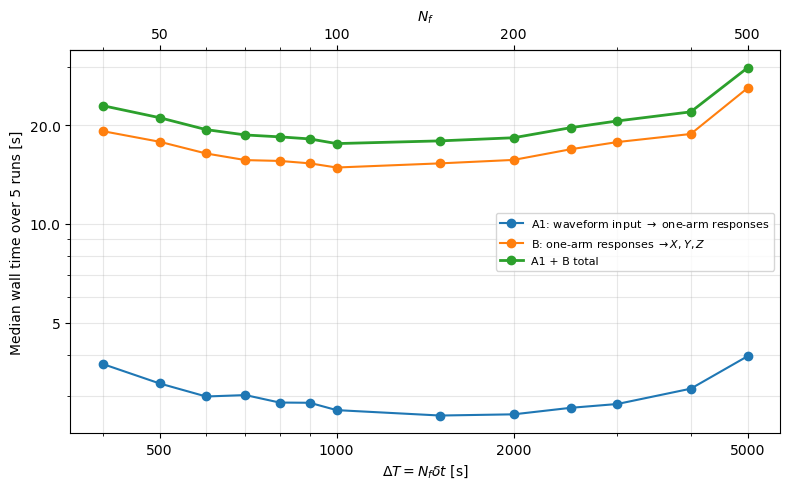

,timing_config_label,assembly_backend,row_chunk_size,lag_block_size,batch_chunk,interp_points,Nf,DeltaT,Nt,coeffs_per_channel,max_mismatch_cut,A0_geometry_precompute_s,A1_waveform_precompute_median_s,A1_waveform_context_build_median_s,A1_six_link_compute_median_s,A1_job_build_median_s,B_downstream_tdi_median_s,total_A1_plus_B_median_s,B_per_job_ms,finite
0,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,40,400.0,80474,3218960,0.000002,17.205183,3.748119,0.286146,3.476649,0.000032,19.167685,22.915804,456.373450,True
1,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,50,500.0,64380,3219000,0.000001,14.027728,3.269400,0.124710,3.148009,0.000032,17.789197,21.058597,423.552318,True
2,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,60,600.0,53650,3219000,0.000001,12.409119,2.983268,0.129730,2.840780,0.000033,16.385308,19.368575,390.126372,True
3,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,70,700.0,45986,3219020,0.000001,11.439635,3.012906,0.250847,2.760779,0.000041,15.640648,18.653554,372.396391,True
4,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,80,800.0,40238,3219040,0.000001,9.924814,2.859279,0.153898,2.704773,0.000034,15.551542,18.410822,370.274818,True
5,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,90,900.0,35766,3218940,0.000002,9.340371,2.854868,0.221062,2.643718,0.000034,15.291876,18.146744,364.092297,True
6,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,100,1000.0,32190,3219000,0.000002,8.650060,2.711474,0.141831,2.565502,0.000033,14.849728,17.561202,353.564961,True
7,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,150,1500.0,21460,3219000,0.000004,6.821660,2.610604,0.132560,2.475804,0.000042,15.287550,17.898154,363.989283,True
8,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,200,2000.0,16096,3219200,0.000007,5.983581,2.632632,0.151336,2.480368,0.000047,15.662528,18.295160,372.917328,True
9,chunked_L25_R2048_BC1_ip16_no_m0,lagfirst_chunked,2048,NaN,1,16,250,2500.0,12876,3219000,0.000012,5.449147,2.755654,0.136498,2.618454,0.000047,16.876408,19.632063,401.819244,True


In [25]:
# -------------------------------------------------------------------
# Plot timing: A1, B, and A1+B only, with clearer axis ticks
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

dt = 10

if "df_timing" not in globals():
    if "timing_final_path" in globals() and timing_final_path.exists():
        df_timing = pd.read_csv(timing_final_path)
    else:
        raise NameError("df_timing is not defined and no timing CSV was found.")

if "TIMING_CONFIG_LABEL" not in globals():
    TIMING_CONFIG_LABEL = "deltaT_timing_config"

df_timing = df_timing.sort_values("DeltaT").reset_index(drop=True)

# Keep only finite positive timing points
required_cols = [
    "DeltaT",
    "Nf",
    "A1_waveform_precompute_median_s",
    "B_downstream_tdi_median_s",
    "total_A1_plus_B_median_s",
]

missing_cols = [c for c in required_cols if c not in df_timing.columns]
if missing_cols:
    raise KeyError(f"Missing columns in df_timing: {missing_cols}")

mask = np.ones(len(df_timing), dtype=bool)

for col in required_cols:
    values = df_timing[col].to_numpy(dtype=float)
    mask &= np.isfinite(values)

mask &= df_timing["DeltaT"].to_numpy(dtype=float) > 0
mask &= df_timing["A1_waveform_precompute_median_s"].to_numpy(dtype=float) > 0
mask &= df_timing["B_downstream_tdi_median_s"].to_numpy(dtype=float) > 0
mask &= df_timing["total_A1_plus_B_median_s"].to_numpy(dtype=float) > 0

dfp = df_timing.loc[mask].copy()

if len(dfp) == 0:
    raise RuntimeError("No finite positive timing points to plot.")


def format_seconds_tick(x, pos=None):
    """
    Compact tick formatter for wall times in seconds.
    """
    if not np.isfinite(x) or x <= 0:
        return ""

    if x >= 100:
        return f"{x:.0f}"
    if x >= 10:
        return f"{x:.1f}"
    if x >= 1:
        return f"{x:.2g}"
    if x >= 1e-3:
        return f"{1e3 * x:.0f} ms"
    return f"{x:.1e}"


def format_deltaT_tick(x):
    """
    Compact formatter for DeltaT tick labels.
    """
    if not np.isfinite(x):
        return ""

    if abs(x - round(x)) < 1e-9:
        return f"{int(round(x))}"

    return f"{x:g}"


fig, ax = plt.subplots(figsize=(8, 5))

ax.loglog(
    dfp["DeltaT"],
    dfp["A1_waveform_precompute_median_s"],
    marker="o",
    label=r"A1: waveform input $\rightarrow$ one-arm responses",
)

ax.loglog(
    dfp["DeltaT"],
    dfp["B_downstream_tdi_median_s"],
    marker="o",
    label=r"B: one-arm responses $\rightarrow X,Y,Z$",
)

ax.loglog(
    dfp["DeltaT"],
    dfp["total_A1_plus_B_median_s"],
    marker="o",
    linewidth=2,
    label=r"A1 + B total",
)

ax.set_xlabel(r"$\Delta T = N_f \delta t$ [s]")
ax.set_ylabel("Median wall time over 5 runs [s]")

# -------------------------------------------------------------------
# Clearer ticks
# -------------------------------------------------------------------

DeltaT_ticks = dfp["DeltaT"].to_numpy(dtype=float)
Nf_ticks = dfp["Nf"].to_numpy(dtype=int)

# If there are not too many points, label every measured DeltaT value.
if len(DeltaT_ticks) <= 12:
    ax.set_xticks(DeltaT_ticks)
    ax.set_xticklabels(
        [format_deltaT_tick(x) for x in DeltaT_ticks],
        rotation=35,
        ha="right",
    )
else:
    ax.xaxis.set_major_locator(
        mticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0))
    )
    ax.xaxis.set_minor_locator(
        mticker.LogLocator(base=10, subs=np.arange(1, 10) * 0.1)
    )
    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, pos: format_deltaT_tick(x))
    )

# More readable y-axis labels.
ax.yaxis.set_major_locator(
    mticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0))
)
ax.yaxis.set_minor_locator(
    mticker.LogLocator(base=10, subs=np.arange(1, 10) * 0.1)
)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(format_seconds_tick))

# Top axis showing corresponding Nf values.
# Since DeltaT = Nf * dt, Nf = DeltaT / dt.
secax = ax.secondary_xaxis(
    "top",
    functions=(
        lambda DeltaT: DeltaT / dt,
        lambda Nf: Nf * dt,
    ),
)

secax.set_xlabel(r"$N_f$")

if len(Nf_ticks) <= 12:
    secax.set_xticks(Nf_ticks)
    secax.set_xticklabels([str(int(x)) for x in Nf_ticks])
else:
    secax.xaxis.set_major_locator(
        mticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0))
    )
    secax.xaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, pos: f"{int(x):d}" if x >= 1 else "")
    )

ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()

timing_plot_path = (
    DELTA_T_SWEEP_DIR
    / f"deltaT_timing_A1_B_total_{TIMING_CONFIG_LABEL}_clean_ticks.pdf"
)

timing_plot_path_png = (
    DELTA_T_SWEEP_DIR
    / f"deltaT_timing_A1_B_total_{TIMING_CONFIG_LABEL}_clean_ticks.png"
)

fig.savefig(timing_plot_path, bbox_inches="tight")
fig.savefig(timing_plot_path_png, dpi=300, bbox_inches="tight")

print("Saved timing plot to:")
print(" ", timing_plot_path)
print(" ", timing_plot_path_png)

plt.show()

display_cols = [
    "timing_config_label",
    "assembly_backend",
    "row_chunk_size",
    "lag_block_size",
    "batch_chunk",
    "interp_points",
    "Nf",
    "DeltaT",
    "Nt",
    "coeffs_per_channel",
    "max_mismatch_cut",
    "A0_geometry_precompute_s",
    "A1_waveform_precompute_median_s",
    "A1_waveform_context_build_median_s",
    "A1_six_link_compute_median_s",
    "A1_job_build_median_s",
    "B_downstream_tdi_median_s",
    "total_A1_plus_B_median_s",
    "B_per_job_ms",
    "finite",
]

display_cols = [c for c in display_cols if c in dfp.columns]

display(dfp[display_cols])


####################################################################################################
Testing block config: R2048_B32_baseline
####################################################################################################
TIMING_SHIFT_KWARGS:
  assembly_backend: lagfirst_chunked_lagblock
  assembly_precision: complex64
  tl_tp_mode: interp
  tl_tp_interp_points: 16
  tl_tp_interp_kind: linear
  tl_tp_interp_backend: auto
  batch_chunk: 1
  row_chunk_size: 2048
  lag_block_size: 32

Timing Nf=100, DeltaT=1.000000e+03 s
A0 static setup:
  geometry_precompute_s: 8.802489
  WDM shape: Nt=32190, Nf=100, N=3219000
  DeltaT from WDM: 1.000000e+03
A1 waveform/one-arm stage:
  A1 median_s:                 1.439412
  waveform_context median_s:   0.141592
  six_link_compute median_s:   1.294012
  job_build median_s:          0.000032
  n_tdi_jobs:                  42
B downstream TDI stage:
  B median_s:                  6.187622
  output shape:                (32190, 100)
 

,config_label,Nf,DeltaT,Nt,coeffs_per_channel,A1_waveform_precompute_median_s,A1_six_link_compute_median_s,B_downstream_tdi_median_s,total_A1_plus_B_median_s,B_per_job_ms,finite
0,R512_B16,100,1000.0,32190,3219000,2.964275,2.819993,17.055304,20.019578,406.078664,True
1,R1024_B16,100,1000.0,32190,3219000,2.773708,2.634295,15.669817,18.443526,373.090889,True
2,R1024_B32,100,1000.0,32190,3219000,1.535263,1.398613,6.538508,8.073772,155.678770,True
3,R2048_B32_baseline,100,1000.0,32190,3219000,1.439412,1.294012,6.187622,7.627033,147.324329,True
4,R512_B16,110,1100.0,29264,3219040,2.956477,2.810543,17.013807,19.970284,405.090632,True
5,R1024_B16,110,1100.0,29264,3219040,2.693271,2.548885,15.234116,17.927386,362.717039,True
6,R1024_B32,110,1100.0,29264,3219040,1.509379,1.365066,6.798496,8.307875,161.868953,True
7,R2048_B32_baseline,110,1100.0,29264,3219040,1.426612,1.280306,6.328566,7.755178,150.680153,True
8,R512_B16,120,1200.0,26826,3219120,2.902669,2.739948,16.746836,19.649506,398.734196,True
9,R1024_B16,120,1200.0,26826,3219120,2.694892,2.520638,15.187328,17.882220,361.603055,True


Saved block-shape plot to: runs/deltaT_sweep_1yr_basepad_stable/deltaT_block_shape_test_B_downstream_TDI_L25_ip16.pdf


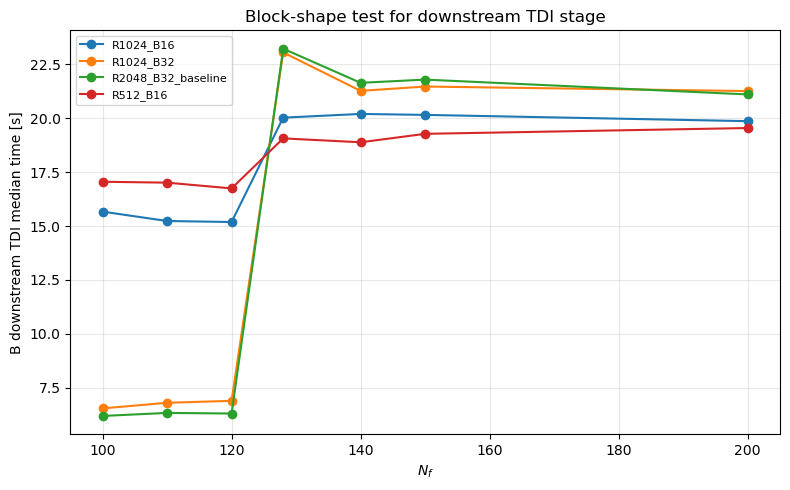

Saved total block-shape plot to: runs/deltaT_sweep_1yr_basepad_stable/deltaT_block_shape_test_A1_plus_B_L25_ip16.pdf


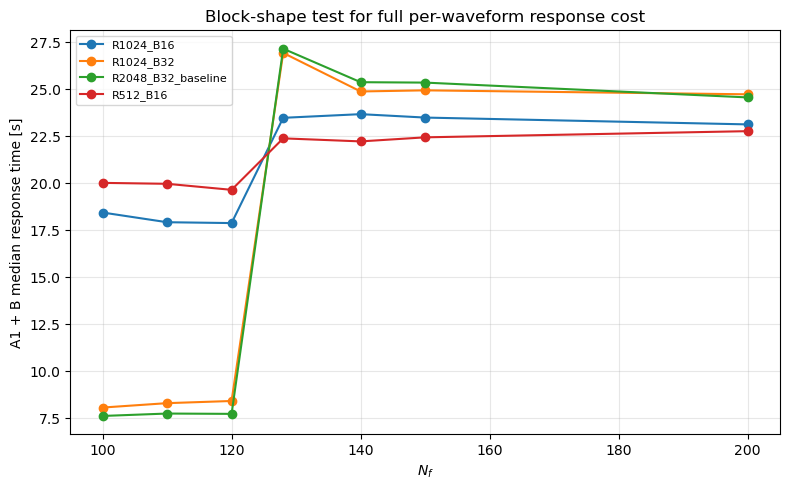

In [28]:
# -------------------------------------------------------------------
# Secondary timing diagnostic:
# Does the high-Nf slowdown come from the fixed block shape?
# -------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy

# Test around the observed transition.
# You can reduce this to [100, 150, 200] for a faster smoke test.
Nf_block_test_grid = [100, 110, 120, 128, 140, 150, 200]

# Fixed shared settings
BASE_TIMING_SHIFT_KWARGS = {
    "assembly_backend": "lagfirst_chunked_lagblock",
    "assembly_precision": "complex64",
    "tl_tp_mode": "interp",
    "tl_tp_interp_points": 16,
    "tl_tp_interp_kind": "linear",
    "tl_tp_interp_backend": "auto",
    "batch_chunk": 1,
}

block_configs = [
    {
        "config_label": "R2048_B32_baseline",
        "row_chunk_size": 2048,
        "lag_block_size": 32,
    },
    {
        "config_label": "R1024_B32",
        "row_chunk_size": 1024,
        "lag_block_size": 32,
    },
    {
        "config_label": "R1024_B16",
        "row_chunk_size": 1024,
        "lag_block_size": 16,
    },
    {
        "config_label": "R512_B16",
        "row_chunk_size": 512,
        "lag_block_size": 16,
    },
]

# Save current globals so the notebook returns to your main timing setup afterwards.
_saved_timing_globals = {
    "TIMING_SHIFT_KWARGS": copy.deepcopy(TIMING_SHIFT_KWARGS),
    "TIMING_L_TRUNC": TIMING_L_TRUNC,
    "A1_WAVE_WARM_RUNS": A1_WAVE_WARM_RUNS,
    "B_TDI_WARM_RUNS": B_TDI_WARM_RUNS,
    "A1_WAVE_REPEAT": A1_WAVE_REPEAT,
    "B_TDI_REPEAT": B_TDI_REPEAT,
}

# Use your intended L=25.
TIMING_L_TRUNC = 25

# Keep median over 5 runs, matching your timing convention.
A1_WAVE_WARM_RUNS = 1
B_TDI_WARM_RUNS = 1
A1_WAVE_REPEAT = 5
B_TDI_REPEAT = 5

block_test_results = []

try:
    for config in block_configs:
        config_label = config["config_label"]

        TIMING_SHIFT_KWARGS = dict(BASE_TIMING_SHIFT_KWARGS)
        TIMING_SHIFT_KWARGS["row_chunk_size"] = int(config["row_chunk_size"])
        TIMING_SHIFT_KWARGS["lag_block_size"] = int(config["lag_block_size"])

        print()
        print("#" * 100)
        print(f"Testing block config: {config_label}")
        print("#" * 100)
        print("TIMING_SHIFT_KWARGS:")
        for k, v in TIMING_SHIFT_KWARGS.items():
            print(f"  {k}: {v}")

        for Nf in Nf_block_test_grid:
            row = run_tdi_deltaT_timing_case(Nf)

            row["config_label"] = config_label
            row["test_row_chunk_size"] = int(config["row_chunk_size"])
            row["test_lag_block_size"] = int(config["lag_block_size"])

            block_test_results.append(row)

            df_block_test = pd.DataFrame(block_test_results)
            df_block_test = df_block_test.sort_values(
                ["Nf", "test_row_chunk_size", "test_lag_block_size"]
            ).reset_index(drop=True)

            block_test_partial_path = (
                DELTA_T_SWEEP_DIR
                / "deltaT_block_shape_test_L25_ip16_partial.csv"
            )
            df_block_test.to_csv(block_test_partial_path, index=False)

            print("Saved partial block-shape test to:", block_test_partial_path)

finally:
    # Restore original timing globals.
    TIMING_SHIFT_KWARGS = _saved_timing_globals["TIMING_SHIFT_KWARGS"]
    TIMING_L_TRUNC = _saved_timing_globals["TIMING_L_TRUNC"]
    A1_WAVE_WARM_RUNS = _saved_timing_globals["A1_WAVE_WARM_RUNS"]
    B_TDI_WARM_RUNS = _saved_timing_globals["B_TDI_WARM_RUNS"]
    A1_WAVE_REPEAT = _saved_timing_globals["A1_WAVE_REPEAT"]
    B_TDI_REPEAT = _saved_timing_globals["B_TDI_REPEAT"]

df_block_test = pd.DataFrame(block_test_results)
df_block_test = df_block_test.sort_values(
    ["Nf", "test_row_chunk_size", "test_lag_block_size"]
).reset_index(drop=True)

block_test_final_path = (
    DELTA_T_SWEEP_DIR
    / "deltaT_block_shape_test_L25_ip16_full.csv"
)
df_block_test.to_csv(block_test_final_path, index=False)

print()
print("Saved final block-shape test to:", block_test_final_path)

display(
    df_block_test[
        [
            "config_label",
            "Nf",
            "DeltaT",
            "Nt",
            "coeffs_per_channel",
            "A1_waveform_precompute_median_s",
            "A1_six_link_compute_median_s",
            "B_downstream_tdi_median_s",
            "total_A1_plus_B_median_s",
            "B_per_job_ms",
            "finite",
        ]
    ]
)

# -------------------------------------------------------------------
# Plot comparison
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

for config_label, grp in df_block_test.groupby("config_label"):
    grp = grp.sort_values("Nf")

    ax.plot(
        grp["Nf"],
        grp["B_downstream_tdi_median_s"],
        marker="o",
        label=config_label,
    )

ax.set_xlabel(r"$N_f$")
ax.set_ylabel(r"B downstream TDI median time [s]")
ax.set_title(r"Block-shape test for downstream TDI stage")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()

block_test_plot_path = (
    DELTA_T_SWEEP_DIR
    / "deltaT_block_shape_test_B_downstream_TDI_L25_ip16.pdf"
)
fig.savefig(block_test_plot_path, bbox_inches="tight")

print("Saved block-shape plot to:", block_test_plot_path)

plt.show()


fig, ax = plt.subplots(figsize=(8, 5))

for config_label, grp in df_block_test.groupby("config_label"):
    grp = grp.sort_values("Nf")

    ax.plot(
        grp["Nf"],
        grp["total_A1_plus_B_median_s"],
        marker="o",
        label=config_label,
    )

ax.set_xlabel(r"$N_f$")
ax.set_ylabel(r"A1 + B median response time [s]")
ax.set_title(r"Block-shape test for full per-waveform response cost")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()

block_test_total_plot_path = (
    DELTA_T_SWEEP_DIR
    / "deltaT_block_shape_test_A1_plus_B_L25_ip16.pdf"
)
fig.savefig(block_test_total_plot_path, bbox_inches="tight")

print("Saved total block-shape plot to:", block_test_total_plot_path)

plt.show()

In [31]:
# -------------------------------------------------------------------
# Dedicated output folder for A_frac / d / lag diagnostics
# -------------------------------------------------------------------

from pathlib import Path
import numpy as np
import pandas as pd

if "DELTA_T_SWEEP_DIR" in globals():
    BASIS_DIAG_DIR = Path(DELTA_T_SWEEP_DIR) / "basis_Afrac_d_diagnostics"
else:
    BASIS_DIAG_DIR = Path("runs") / "basis_Afrac_d_diagnostics"

BASIS_GRID_DIR = BASIS_DIAG_DIR / "Afrac_d_grid"
BASIS_QUICK_DIR = BASIS_DIAG_DIR / "quick_checks"
BASIS_LAG_DIR = BASIS_DIAG_DIR / "Afrac_lag_checks"
BASIS_TABLE_DIR = BASIS_DIAG_DIR / "tables"

for folder in [
    BASIS_DIAG_DIR,
    BASIS_GRID_DIR,
    BASIS_QUICK_DIR,
    BASIS_LAG_DIR,
    BASIS_TABLE_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Basis diagnostics folder:")
print(" ", BASIS_DIAG_DIR.resolve())
print()
print("Subfolders:")
print(" ", BASIS_GRID_DIR.resolve())
print(" ", BASIS_QUICK_DIR.resolve())
print(" ", BASIS_LAG_DIR.resolve())
print(" ", BASIS_TABLE_DIR.resolve())

Basis diagnostics folder:
  /data/tk593/LISA_Response/LISAresponse/WDM_LISAresponse/examples/runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_diagnostics

Subfolders:
  /data/tk593/LISA_Response/LISAresponse/WDM_LISAresponse/examples/runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_diagnostics/Afrac_d_grid
  /data/tk593/LISA_Response/LISAresponse/WDM_LISAresponse/examples/runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_diagnostics/quick_checks
  /data/tk593/LISA_Response/LISAresponse/WDM_LISAresponse/examples/runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_diagnostics/Afrac_lag_checks
  /data/tk593/LISA_Response/LISAresponse/WDM_LISAresponse/examples/runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_diagnostics/tables


In [32]:
# -------------------------------------------------------------------
# Reload patched WDM_GW_wavelets time-shift module and response/TDI modules
# -------------------------------------------------------------------

import importlib
import inspect
import WDM
import WDM.code.time_delay_filters.time_shift_fast as tsf

print("time_shift_fast path:")
print(tsf.__file__)

tsf = importlib.reload(tsf)

import WDM_LISAresponse.code.lisa_response.response as response_module
import WDM_LISAresponse.code.lisa_response.TDI as TDI_module

response_module = importlib.reload(response_module)
TDI_module = importlib.reload(TDI_module)

from WDM_LISAresponse.code.lisa_response.TDI import gen2_michelson_wdm

def clear_wdm_kernel_caches():
    for name in ["_KERNEL_WDM_CACHE", "_KERNEL_PRECOMP_CACHE", "_CNM_PARITY_CACHE"]:
        cache = getattr(tsf, name, None)
        if hasattr(cache, "clear"):
            cache.clear()
            print(f"Cleared tsf.{name}")

print()
print("Reloaded patched modules.")
print("_inherit_kernel_wdm_kwargs exists:", hasattr(tsf, "_inherit_kernel_wdm_kwargs"))

try:
    src = inspect.getsource(tsf._build_kernel_wdm_like)
    print("A_frac appears in _build_kernel_wdm_like:", "A_frac" in src)
    print("_inherit_kernel_wdm_kwargs used:", "_inherit_kernel_wdm_kwargs" in src)
except Exception as exc:
    print("Could not inspect _build_kernel_wdm_like:")
    print(exc)

clear_wdm_kernel_caches()

time_shift_fast path:
/data/tk593/LISA_Response/LISAresponse/WDM_GW_wavelets/src/WDM/code/time_delay_filters/time_shift_fast.py

Reloaded patched modules.
_inherit_kernel_wdm_kwargs exists: True
A_frac appears in _build_kernel_wdm_like: False
_inherit_kernel_wdm_kwargs used: True
Cleared tsf._KERNEL_WDM_CACHE
Cleared tsf._KERNEL_PRECOMP_CACHE
Cleared tsf._CNM_PARITY_CACHE


In [33]:
# -------------------------------------------------------------------
# Direct sanity check: kernel WDM should inherit A_frac
# -------------------------------------------------------------------

def check_kernel_Afrac_inheritance(A_frac_test, Nf_test=100, d_test=4, L_test=25):
    clear_wdm_kernel_caches()

    dt_test = float(globals().get("dt", 10.0))
    N_test = int(20000)

    wdm_data = WDM.WDM.WDM_transform(
        dt=dt_test,
        Nf=int(Nf_test),
        N=N_test,
        q=1,
        calc_m0=False,
        d=int(d_test),
        A_frac=float(A_frac_test),
    )

    Nker = tsf.choose_Nker(int(L_test), int(Nf_test))

    wdm_ker = tsf._build_kernel_wdm_like(
        wdm_data,
        Nker=Nker,
        Nf=int(Nf_test),
        d=int(d_test),
        calc_m0=True,
    )

    data_A = float(getattr(wdm_data, "A_frac", np.nan))
    ker_A = float(getattr(wdm_ker, "A_frac", np.nan))

    print()
    print("=" * 80)
    print(f"A_frac inheritance check: A_frac={A_frac_test}")
    print("=" * 80)
    print("data WDM A_frac:  ", data_A)
    print("kernel WDM A_frac:", ker_A)
    print("Nker:             ", Nker)

    if not np.isclose(data_A, ker_A):
        raise RuntimeError(
            f"Kernel WDM did not inherit A_frac: data={data_A}, kernel={ker_A}"
        )

    return wdm_data, wdm_ker


wdm_data_020, wdm_ker_020 = check_kernel_Afrac_inheritance(0.20)
wdm_data_025, wdm_ker_025 = check_kernel_Afrac_inheritance(0.25)
wdm_data_030, wdm_ker_030 = check_kernel_Afrac_inheritance(0.30)

assert wdm_ker_020 is not wdm_ker_030

print()
print("Kernel A_frac inheritance checks passed.")

Cleared tsf._KERNEL_WDM_CACHE
Cleared tsf._KERNEL_PRECOMP_CACHE
Cleared tsf._CNM_PARITY_CACHE

A_frac inheritance check: A_frac=0.2
data WDM A_frac:   0.2
kernel WDM A_frac: 0.2
Nker:              5200
Cleared tsf._KERNEL_WDM_CACHE
Cleared tsf._KERNEL_PRECOMP_CACHE
Cleared tsf._CNM_PARITY_CACHE

A_frac inheritance check: A_frac=0.25
data WDM A_frac:   0.25
kernel WDM A_frac: 0.25
Nker:              5200
Cleared tsf._KERNEL_WDM_CACHE
Cleared tsf._KERNEL_PRECOMP_CACHE
Cleared tsf._CNM_PARITY_CACHE

A_frac inheritance check: A_frac=0.3
data WDM A_frac:   0.3
kernel WDM A_frac: 0.3
Nker:              5200

Kernel A_frac inheritance checks passed.


In [34]:
# -------------------------------------------------------------------
# Check run_deltaT_case interface
# -------------------------------------------------------------------

import inspect

if "run_deltaT_case" not in globals():
    raise NameError(
        "run_deltaT_case is not defined. Re-run the patched run_deltaT_case cell first."
    )

sig = inspect.signature(run_deltaT_case)
print("run_deltaT_case signature:", sig)

if "A_frac" not in sig.parameters or "d" not in sig.parameters:
    raise RuntimeError(
        "run_deltaT_case must have signature like:\n"
        "    run_deltaT_case(Nf, *, A_frac=None, d=None)\n"
        "Patch/re-run the explicit A_frac/d version before continuing."
    )

print("run_deltaT_case explicit A_frac/d support confirmed.")

run_deltaT_case signature: (Nf, *, A_frac=None, d=None)
run_deltaT_case explicit A_frac/d support confirmed.


In [42]:
# -------------------------------------------------------------------
# Final small local A_frac x d robustness grid
# -------------------------------------------------------------------

from pathlib import Path
import numpy as np
import pandas as pd

# Dedicated folder for final basis-parameter robustness check
if "DELTA_T_SWEEP_DIR" in globals():
    BASIS_FINAL_DIR = Path(DELTA_T_SWEEP_DIR) / "basis_Afrac_d_final"
else:
    BASIS_FINAL_DIR = Path("runs") / "basis_Afrac_d_final"

BASIS_FINAL_DIR.mkdir(parents=True, exist_ok=True)

Nf_basis_grid = 100
L_basis_grid = 25

# Small local grid around the default basis choice
A_frac_grid = [0.2, 0.25, 0.3]
d_grid = [2, 4, 6]

basis_grid_settings = []

for A_val in A_frac_grid:
    if not (0.0 < float(A_val) < 0.5):
        raise ValueError(f"Invalid A_frac={A_val}. Need 0 < A_frac < 0.5.")

    for d_val in d_grid:
        basis_grid_settings.append(
            {
                "A_frac": float(A_val),
                "B_frac": float(1.0 - 2.0 * float(A_val)),
                "d": int(d_val),
                "label": f"A_frac={A_val:.3f}, d={int(d_val)}",
            }
        )

basis_grid_partial_path = (
    BASIS_FINAL_DIR
    / f"local_basis_grid_Afrac_d_Nf{Nf_basis_grid}_L{L_basis_grid}_partial.csv"
)

basis_grid_final_path = (
    BASIS_FINAL_DIR
    / f"local_basis_grid_Afrac_d_Nf{Nf_basis_grid}_L{L_basis_grid}_full.csv"
)

# Fresh run
for path in [basis_grid_partial_path, basis_grid_final_path]:
    if path.exists():
        path.unlink()
        print("Removed old file:", path)

basis_grid_results = []

mismatch_cols = [
    "X_mismatch_cut",
    "Y_mismatch_cut",
    "Z_mismatch_cut",
    "link_12_mismatch_cut",
]

_saved_L_trunc_value = int(globals().get("L_trunc_value", 25))

try:
    L_trunc_value = int(L_basis_grid)

    for setting in basis_grid_settings:
        print()
        print("#" * 90)
        print(f"Local basis grid case: {setting['label']}, L={L_basis_grid}")
        print("#" * 90)

        try:
            clear_wdm_kernel_caches()
        except NameError:
            pass

        row = run_deltaT_case(
            Nf_basis_grid,
            A_frac=setting["A_frac"],
            d=setting["d"],
        )

        row["label"] = setting["label"]
        row["A_frac"] = float(setting["A_frac"])
        row["B_frac"] = float(setting["B_frac"])
        row["d"] = int(setting["d"])
        row["L_trunc"] = int(L_basis_grid)

        row["max_mismatch_cut"] = float(
            np.nanmax([row[col] for col in mismatch_cols])
        )

        basis_grid_results.append(row)

        df_basis_grid = pd.DataFrame(basis_grid_results)
        df_basis_grid = df_basis_grid.sort_values(["A_frac", "d"]).reset_index(drop=True)
        df_basis_grid.to_csv(basis_grid_partial_path, index=False)

        print("Saved partial grid to:", basis_grid_partial_path)

finally:
    L_trunc_value = _saved_L_trunc_value

df_basis_grid = pd.DataFrame(basis_grid_results)
df_basis_grid = df_basis_grid.sort_values(["A_frac", "d"]).reset_index(drop=True)
df_basis_grid.to_csv(basis_grid_final_path, index=False)

print()
print("Saved final grid to:", basis_grid_final_path)

display(
    df_basis_grid[
        [
            "A_frac",
            "B_frac",
            "d",
            "L_trunc",
            "X_mismatch_cut",
            "Y_mismatch_cut",
            "Z_mismatch_cut",
            "link_12_mismatch_cut",
            "max_mismatch_cut",
        ]
    ]
)

Removed old file: runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_final/local_basis_grid_Afrac_d_Nf100_L25_partial.csv
Removed old file: runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_final/local_basis_grid_Afrac_d_Nf100_L25_full.csv

##########################################################################################
Local basis grid case: A_frac=0.200, d=2, L=25
##########################################################################################
Cleared tsf._KERNEL_WDM_CACHE
Cleared tsf._KERNEL_PRECOMP_CACHE
Cleared tsf._CNM_PARITY_CACHE

Running Nf=100, DeltaT=1.000000e+03 s
  A_frac=0.2
  d=2
Shift settings:
  backend:        lagfirst_chunked_lagblock
  row_chunk_size: 2048
  lag_block_size: 32
  job_block_size: -
Grid estimate:
  base length:    3218932
  old pad length: 3219000
  target length:  3219000
  Nt estimate:    32190
  coeffs/channel: 3,219,000
  direct WDM XYZ stage: 17.934 s
  extracted direct WDM dl_12 from one-arm cache.
  dl_12 extraction stage: 

,A_frac,B_frac,d,L_trunc,X_mismatch_cut,Y_mismatch_cut,Z_mismatch_cut,link_12_mismatch_cut,max_mismatch_cut
0,0.20,0.6,2,25,8.353649e-07,0.000001,0.000001,8.155599e-07,0.000001
1,0.20,0.6,4,25,1.047729e-06,0.000002,0.000001,1.051597e-06,0.000002
2,0.20,0.6,6,25,1.259482e-06,0.000002,0.000002,1.276763e-06,0.000002
3,0.25,0.5,2,25,1.027786e-06,0.000002,0.000001,1.015664e-06,0.000002
4,0.25,0.5,4,25,1.246830e-06,0.000002,0.000002,1.260805e-06,0.000002
5,0.25,0.5,6,25,1.499222e-06,0.000003,0.000002,1.529582e-06,0.000003
6,0.30,0.4,2,25,1.465557e-06,0.000002,0.000002,1.474039e-06,0.000002
7,0.30,0.4,4,25,1.543365e-06,0.000003,0.000002,1.574244e-06,0.000003
8,0.30,0.4,6,25,1.951763e-06,0.000003,0.000003,1.976326e-06,0.000003


In [43]:
# -------------------------------------------------------------------
# Diagnostic pivot table: max mismatch over A_frac and d
# -------------------------------------------------------------------

if "df_basis_grid" not in globals():
    raise NameError("df_basis_grid is not defined. Run the local basis grid first.")

df_basis_grid = df_basis_grid.copy()

mismatch_cols = [
    "X_mismatch_cut",
    "Y_mismatch_cut",
    "Z_mismatch_cut",
    "link_12_mismatch_cut",
]

df_basis_grid["max_mismatch_cut"] = df_basis_grid[mismatch_cols].max(axis=1)

pivot_max = df_basis_grid.pivot(
    index="A_frac",
    columns="d",
    values="max_mismatch_cut",
)

pivot_logmax = np.log10(pivot_max)

pivot_max_path = (
    BASIS_FINAL_DIR
    / f"local_basis_grid_Afrac_d_Nf{Nf_basis_grid}_L{L_basis_grid}_pivot_max.csv"
)

pivot_logmax_path = (
    BASIS_FINAL_DIR
    / f"local_basis_grid_Afrac_d_Nf{Nf_basis_grid}_L{L_basis_grid}_pivot_log10_max.csv"
)

pivot_max.to_csv(pivot_max_path)
pivot_logmax.to_csv(pivot_logmax_path)

print("Max mismatch:")
display(pivot_max)

print()
print("log10(max mismatch):")
display(pivot_logmax)

print()
print("Saved pivot tables:")
print(" ", pivot_max_path)
print(" ", pivot_logmax_path)

Max mismatch:


d,2,4,6
A_frac,,,
0.20,0.000001,0.000002,0.000002
0.25,0.000002,0.000002,0.000003
0.30,0.000002,0.000003,0.000003



log10(max mismatch):


d,2,4,6
A_frac,,,
0.20,-5.876879,-5.761519,-5.679074
0.25,-5.787982,-5.683975,-5.601435
0.30,-5.653777,-5.588773,-5.493843



Saved pivot tables:
  runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_final/local_basis_grid_Afrac_d_Nf100_L25_pivot_max.csv
  runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_final/local_basis_grid_Afrac_d_Nf100_L25_pivot_log10_max.csv


In [44]:
# -------------------------------------------------------------------
# Final report-style A_frac x d table in thesis LaTeX style
# -------------------------------------------------------------------

if "df_basis_grid" not in globals():
    raise NameError("df_basis_grid is not defined. Run the local basis grid first.")

df_basis_report_table = df_basis_grid.sort_values(["A_frac", "d"]).reset_index(drop=True)

df_basis_report_table = df_basis_report_table[
    [
        "A_frac",
        "d",
        "X_mismatch_cut",
        "Y_mismatch_cut",
        "Z_mismatch_cut",
        "link_12_mismatch_cut",
    ]
].copy()


def latex_sci(x, sig=3):
    """
    Format a number as LaTeX scientific notation:
    1.23e-06 -> $1.23\\times 10^{-6}$
    """
    x = float(x)
    if x == 0.0:
        return "$0$"

    s = f"{x:.{sig}e}"
    mantissa, exponent = s.split("e")
    exponent = int(exponent)

    # Remove unnecessary trailing zeros in mantissa
    mantissa = mantissa.rstrip("0").rstrip(".")

    return rf"${mantissa}\times 10^{{{exponent}}}$"


def latex_decimal(x, ndp=3):
    """
    Format A_frac normally, not in scientific notation.
    """
    return f"{float(x):.{ndp}f}"


# Build rows manually to match your preferred table style
rows = []

for _, row in df_basis_report_table.iterrows():
    rows.append(
        "        "
        + " & ".join(
            [
                latex_decimal(row["A_frac"], ndp=3),
                f"{int(row['d'])}",
                latex_sci(row["X_mismatch_cut"], sig=3),
                latex_sci(row["Y_mismatch_cut"], sig=3),
                latex_sci(row["Z_mismatch_cut"], sig=3),
                latex_sci(row["link_12_mismatch_cut"], sig=3),
            ]
        )
        + r"  \\"
    )

latex_lines = []

latex_lines.append(r"\begin{table}[!h]")
latex_lines.append(r"    \centering")
latex_lines.append(r"    \begin{tabular}{|c|c|c|c|c|c|}")
latex_lines.append(r"    \hline")
latex_lines.append(
    r"        $A_{\rm frac}$ & $d$ & $\mathcal{M}_{X}$ & $\mathcal{M}_{Y}$ & $\mathcal{M}_{Z}$ & $\mathcal{M}_{12}$  \\"
)
latex_lines.append(r"    \hline")

for row_line in rows:
    latex_lines.append(row_line)
    latex_lines.append(r"    \hline")

latex_lines.append(r"    \end{tabular}")
latex_lines.append(
    r"    \caption{Sensitivity of the WDM response accuracy to the internal WDM basis parameters $A_{\rm frac}$ and $d$ at fixed $N_f=100$. All other response, interpolation, lag-truncation, and boundary-cut settings are held fixed.}"
)
latex_lines.append(r"    \label{tab:Afrac-d-sensitivity}")
latex_lines.append(r"\end{table}")

latex_string = "\n".join(latex_lines)

latex_path = (
    BASIS_FINAL_DIR
    / f"local_basis_grid_Afrac_d_Nf{Nf_basis_grid}_L{L_basis_grid}_styled_latex_table.txt"
)

with open(latex_path, "w") as f:
    f.write(latex_string)

print("Saved styled LaTeX table to:", latex_path)
print()
print(latex_string)

Saved styled LaTeX table to: runs/deltaT_sweep_1yr_basepad_stable/basis_Afrac_d_final/local_basis_grid_Afrac_d_Nf100_L25_styled_latex_table.txt

\begin{table}[!h]
    \centering
    \begin{tabular}{|c|c|c|c|c|c|}
    \hline
        $A_{\rm frac}$ & $d$ & $\mathcal{M}_{X}$ & $\mathcal{M}_{Y}$ & $\mathcal{M}_{Z}$ & $\mathcal{M}_{12}$  \\
    \hline
        0.200 & 2 & $8.354\times 10^{-7}$ & $1.328\times 10^{-6}$ & $1.104\times 10^{-6}$ & $8.156\times 10^{-7}$  \\
    \hline
        0.200 & 4 & $1.048\times 10^{-6}$ & $1.732\times 10^{-6}$ & $1.384\times 10^{-6}$ & $1.052\times 10^{-6}$  \\
    \hline
        0.200 & 6 & $1.259\times 10^{-6}$ & $2.094\times 10^{-6}$ & $1.657\times 10^{-6}$ & $1.277\times 10^{-6}$  \\
    \hline
        0.250 & 2 & $1.028\times 10^{-6}$ & $1.629\times 10^{-6}$ & $1.335\times 10^{-6}$ & $1.016\times 10^{-6}$  \\
    \hline
        0.250 & 4 & $1.247\times 10^{-6}$ & $2.07\times 10^{-6}$ & $1.641\times 10^{-6}$ & $1.261\times 10^{-6}$  \\
    \hline
       